# Pérdida esperada (ECL) – Lending Club: modelo de PD

Segundo de los tres notebooks del proyecto. Construye la **PD** (probabilidad de impago) de cada préstamo, la primera pieza del ECL:

ECL_i = PD_i × LGD_i × EAD_i

| Notebook | Qué hace |
|---|---|
| **`01_eda.ipynb`** | Carga, EDA, preparación de los datos (transformaciones fijas, split y variables nuevas). Guarda los datos preparados en `data/processed/` |
| **`02_modelo_pd.ipynb`** | Preprocesado, selección de variables y **modelo de PD**. Guarda la PD de validación y test |
| **`03_ead_lgd_ecl.ipynb`** | Targets y modelos de **EAD y LGD**, ECL, margen conservador y resultado final en test |

Los notebooks se ejecutan **en orden**: cada uno lee los ficheros que deja el anterior en `data/processed/`. Python no comparte variables entre notebooks, así que pasar los datos por disco es la forma de encadenarlos.

### Estructura
1. Carga de los datos preparados en `01_eda.ipynb`.
2. Preprocesado: outliers e imputación de nulos.
3. Selección de variables: relevancia (IV) y redundancia (VIF).
4. Preprocesadores de la logística y de LightGBM.
5. Experimentos en validación: logística frente a LightGBM, con tres conjuntos de variables.
6. Ajuste de hiperparámetros de LightGBM.
7. Modelo de PD final, reentrenado con todo train, y su calibración.
8. Exportación de la PD para `03_ead_lgd_ecl.ipynb`.

## 1. Carga de los datos preparados

**Qué hace**: lee train, validación y test tal y como los dejó `01_eda.ipynb` (sección 6), con las transformaciones fijas, el split y las variables nuevas ya aplicados, y las listas de variables de `variables.json`.

Define también lo que este notebook reutiliza de `01_eda.ipynb`: los colores de los gráficos (azul = no impago, naranja = impago) y dos funciones del EDA, `information_value` (4.7 de `01_eda.ipynb`) y `tabla_train` (5.4 de `01_eda.ipynb`), que hacen falta para el ranking de IV de la sección 3.

**Cómo leer la salida**: el tamaño y la tasa de impago de cada parte. El assert comprueba que son las partes del split de `01_eda.ipynb` (5.2).

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

RUTA_DATOS = "data/processed"
train, val, test = (pd.read_pickle(f"{RUTA_DATOS}/{p}.pkl") for p in ("train", "val", "test"))
with open(f"{RUTA_DATOS}/variables.json", encoding="utf-8") as f:
    v = json.load(f)
continuas, conteos, categoricas = v["continuas"], v["conteos"], v["categoricas"]
vars_nuevas, performance, forbidden = v["vars_nuevas"], v["performance"], v["forbidden"]
assert (len(train), len(val), len(test)) == (1_369_371, 342_343, 427_929), "No son las partes de 01_eda.ipynb"

# Lo que se reutiliza de 01_eda.ipynb: colores y funciones del EDA
COLOR_NO_IMPAGO, COLOR_IMPAGO = "#2a78d6", "#eb6834"
COLOR_REF = "#52514e"


def information_value(t):
    """IV = suma de (%no_impago - %impago) * ln(%no_impago / %impago) sobre los grupos."""
    buenos = (t["n"] - t["n_impagos"]) / (t["n"] - t["n_impagos"]).sum()
    malos = t["n_impagos"] / t["n_impagos"].sum()
    buenos, malos = buenos.clip(lower=1e-6), malos.clip(lower=1e-6)   # evita log(0) en grupos vacíos
    return ((buenos - malos) * np.log(buenos / malos)).sum()


def tabla_train(clave, datos=None):
    """Tamaño, impagos y tasa de impago por grupo, sobre train."""
    datos = train if datos is None else datos
    t = datos.groupby(clave, observed=True)["impago"].agg(n="size", n_impagos="sum", tasa_impago="mean")
    t.index.name = clave.name
    return t


pd.DataFrame({"n_prestamos": [len(p) for p in (train, val, test)],
              "tasa_impago_pct": [p["impago"].mean() * 100 for p in (train, val, test)]},
             index=["train", "validación", "test"]).round(2)

,n_prestamos,tasa_impago_pct
train,1369371,13.07
validación,342343,13.07
test,427929,13.07


## 2. Preprocesado: outliers e imputación de nulos

En esta sección se preparan las piezas que corrigen los outliers y los nulos. A diferencia de las transformaciones de `01_eda.ipynb`, estas **aprenden de los datos** (el percentil 99 para winsorizar, la mediana para imputar...), así que se calculan **solo con train** y se aplican tal cual a validación y test.

Las piezas no se aplican todavía: se definen y se comprueban aquí, y entrarán **dentro del pipeline de cada modelo** (sección 4).

### 2.1 Outliers según el método IQR (solo train)

Contamos, para cada variable numérica, cuántos préstamos quedan fuera de las **vallas de Tukey** (la regla del boxplot):

- IQR = Q3 − Q1 (rango intercuartílico: la anchura del 50% central de los datos)
- outlier si el valor es < Q1 − 1,5·IQR o > Q3 + 1,5·IQR

Se calcula **solo con train**, porque esta tabla sirve para decidir tratamientos y no debemos mirar validación ni test. Los nulos no se cuentan (el % es sobre los préstamos con dato).

**Cómo leerla:**
- **Conteos con IQR = 0** (`num_30+_delinq_in_2yrs`, `num_derogatory_pub_rec`): más del 75% de los préstamos vale 0, así que Q1 = Q3 = 0 y **cualquier valor distinto de 0 cuenta como outlier**. Por eso salen arriba del todo (19% y 16%), pero ese número no significa nada.
- **Variables muy asimétricas** (`annual_income`, `total_credit_revolving_bal`, `max_bal_owed`): entre el 5% y el 6% de outliers. Tukey está pensado para distribuciones más o menos simétricas, y aquí marca como outliers a muchos clientes que simplemente tienen ingresos o saldos altos.
- **Prácticamente sin outliers**: `used_credit_share`, `dept_paym_income_ratio`, `bal_to_cred_lim`, las `mths_since_*_delinq` y `emp_length_num`.

El número de outliers dice **cuántos** valores están lejos, pero no **qué hacer** con ellos. Para eso está la tabla de 2.2.

In [2]:
def n_outliers_iqr(x):
    """Número de valores fuera de las vallas de Tukey: Q1 - 1,5·IQR y Q3 + 1,5·IQR."""
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()

# Numéricas de originación (las mismas del EDA), calculado SOLO sobre train y sin contar nulos
num_vars = continuas + list(conteos)
n_out = pd.Series({col: n_outliers_iqr(train[col].dropna()) for col in num_vars})
tabla_iqr = pd.DataFrame({
    "n_outliers": n_out,
    "% outliers": n_out / train[num_vars].notna().sum() * 100,
}).sort_values("n_outliers", ascending=False)
tabla_iqr.round(2)

,n_outliers,% outliers
num_30+_delinq_in_2yrs,257582,18.81
num_derogatory_pub_rec,217747,15.90
num_inq,99800,12.24
total_credit_revolving_bal,83205,6.08
num_open_trades_in_6mths,76361,9.37
mths_since_last_installment_acc_op,68363,8.66
annual_income,64585,4.72
num_inq_in_12mths,64560,4.71
num_inq_in_6mths,59088,4.31
num_open_credit_lines,51559,3.77


### 2.2 Asimetría y curtosis: qué tratamiento aplicar (solo train)

Para decidir entre **no hacer nada, logaritmo, winsorizar o capping** miramos la **forma** de cada distribución:

- **Asimetría** (skewness): si la cola está solo a un lado. 0 = simétrica; **> 1 = muy asimétrica a la derecha** (unos pocos valores muy grandes, como ingresos o saldos).
- **Curtosis** (en exceso; la normal vale 0): cuánto pesan las colas, es decir, los valores extremos. **> 3 = colas pesadas**. Es muy sensible a los propios outliers: con un ingreso de 110 millones sale una cifra enorme, así que hay que leer el orden de magnitud, no el número exacto.
- **Asimetría tras log**: la asimetría que queda si aplicamos log(1 + x). Así vemos directamente **si el logaritmo arregla el problema** (si queda cerca de 0).

**Cómo usar la tabla para decidir** (orientativo):

| Lo que se ve | Tratamiento |
|---|---|
| Asimetría y curtosis bajas | **Nada** |
| Muy asimétrica (> 1), positiva, y el log la deja cerca de 0 (importes) | **Logaritmo** |
| Curtosis alta y el log no la arregla (conteos, variables con muchos ceros) | **Winsorizar** en un percentil calculado en train (p. ej. el 99) |
| Existe un límite lógico de negocio (un % de uso razonable, agrupar un conteo en "k+") | **Capping**: tope fijo elegido por criterio |

Winsorizar y hacer capping recortan igual (`clip`). La diferencia es **de dónde sale el umbral**: en la winsorización es un percentil, que se aprende de train; en el capping es un valor fijo que decidimos nosotros.

**Qué se observa:**
- **`annual_income`**: asimetría 522 y curtosis de cientos de miles, por el máximo de 110 millones. **El logaritmo la deja casi simétrica (0,24)**: es el caso de libro para aplicar log.
- **`max_bal_owed` y `total_credit_revolving_bal`**: muy asimétricas (13–18), pero el logaritmo **se pasa** y deja la asimetría en −2,6 / −3,2. Ocurre porque tienen muchos ceros: log(1 + 0) = 0 forma un bloque separado a la izquierda. Aquí encaja mejor **winsorizar**.
- **`num_derogatory_pub_rec` y `num_30+_delinq_in_2yrs`**: curtosis muy alta (786 y 81) y el log no la arregla (asimetría ~2,4 tras log). Son conteos casi todos a 0: lo natural es **capping en "k+"**, como en el EDA.
- **Resto de conteos de buró y `mths_since_last_installment_acc_op`**: asimetría 1,3–3,4 y curtosis 3–17. El log las deja razonables (entre −0,2 y 0,9), pero al ser conteos discretos también encaja un **capping**.
- **Sin tratamiento necesario** (asimetría < 1,1 y curtosis < 2): `interest_rate`, `funded_amnt`, `monthly_payment`, `dept_paym_income_ratio`, `credit_hist_years`, `tot_num_credit_lines`, las `mths_since_*_delinq` y `emp_length_num`.
- **`used_credit_share` y `bal_to_cred_lim`**: casi simétricas y con curtosis baja; sus valores por encima del 100% son tan pocos que no cambian la forma. Si se tratan, sería con un **capping** de negocio.

La decisión final (qué variables se tratan y para qué modelo) está en 2.3.

In [3]:
# Forma de cada distribución en train: asimetría, curtosis (en exceso) y asimetría tras log(1 + x)
forma = pd.DataFrame({
    "asimetría": train[num_vars].skew(),
    "curtosis": train[num_vars].kurt(),
    "asimetría tras log": np.log1p(train[num_vars]).skew(),   # todas son >= 0, log1p no da problemas
}).sort_values("curtosis", ascending=False)
forma.round(2)

,asimetría,curtosis,asimetría tras log
annual_income,522.23,406692.15,0.24
max_bal_owed,18.49,2662.61,-3.15
num_derogatory_pub_rec,11.59,786.35,2.45
total_credit_revolving_bal,12.96,656.75,-2.63
num_30+_delinq_in_2yrs,6.04,81.04,2.38
mths_since_last_installment_acc_op,3.43,17.31,0.21
num_inq_in_12mths,2.82,14.95,0.58
num_inq,2.66,13.25,0.79
num_inq_in_6mths,2.09,11.02,0.94
num_rev_trades_op_in_24mths,1.99,8.53,-0.09


### 2.3 Tratamiento de outliers: solo en la logística y de forma conservadora

**Cada modelo recibe un tratamiento distinto:**

| | Árboles (boosting) | Regresión logística |
|---|---|---|
| Errores (DTI −1 → NaN) | Sí (hecho en 5.1 de `01_eda.ipynb`, común) | Sí (hecho en 5.1 de `01_eda.ipynb`, común) |
| Log, winsorización, capping | **No** | **Sí**, solo en las variables de la tabla de abajo |

- **Por qué los árboles no lo necesitan**: dividen por umbrales ("¿ingresos ≤ 85.000?"), así que solo importa el **orden** de los valores, no su magnitud. Un ingreso de 110 millones es simplemente "el más alto". El logaritmo no cambia ningún corte y tampoco extrapolan. El sobreajuste en los extremos se controla con sus hiperparámetros (en LightGBM, `min_child_samples` y `num_leaves`).
- **Por qué la logística sí**: el logit es lineal en cada variable, así que unos pocos valores extremos tienen mucha **palanca** sobre el coeficiente. Además, la PD se extrapola hacia 0 o 1 en valores que casi no existen en los datos, y el escalado queda distorsionado.

**Selección conservadora**: solo tratamos las variables con una cola claramente problemática (max/p99 muy alto en 2.1/2.2). El resto se deja como está, aunque Tukey marque outliers.

| Tratamiento | Variables | Motivo |
|---|---|---|
| **Logaritmo** log(1 + x) | `annual_income` | max/p99 = 400; el log deja la asimetría en 0,24 y **no recorta nada** |
| **Winsorizar** en el p99 de train | `total_credit_revolving_bal`, `max_bal_owed` | max/p99 de 30 y 47; el log no sirve por la cantidad de ceros |
| **Capping fijo** | `num_30+_delinq_in_2yrs` ≤ 4, `num_derogatory_pub_rec` ≤ 3 | max/p99 de 14,5 y 43; en el EDA (4.5 de `01_eda.ipynb`) la tasa de impago ya es plana en esa cola |

**Los "outliers de Tukey" de los conteos no se recortan.** En `num_30+_delinq_in_2yrs` más del 75% vale 0, así que Tukey marca a cualquier cliente con 1 retraso, y ese retraso es justo la información útil. Con el tope "4+", los valores 0, 1, 2 y 3 se mantienen distintos y solo se agrupa la cola extrema.

**Implementación.** Dos clases con la interfaz de scikit-learn (`fit` / `transform`):
- **`Winsorizer`**: en `fit` aprende el percentil 99 de cada columna (solo con train) y en `transform` recorta con esos mismos topes. Es la única pieza que aprende de los datos.
- **`CappingFijo`**: recorta en topes fijos que decidimos nosotros. No aprende nada, pero tiene la misma interfaz para poder ir en el pipeline.
- El logaritmo es un `FunctionTransformer(np.log1p)`.

Las tres se juntan en un **`ColumnTransformer`** (`outliers_logit`), que aplica cada tratamiento a sus columnas y deja pasar el resto sin cambios (`remainder="passthrough"`). Esta pieza irá **dentro del pipeline de la logística**: así se ajusta con `fit(train)` y cualquier préstamo nuevo (validación, test) pasa exactamente por las mismas transformaciones. Por eso **no transformamos ahora `train`, `val` ni `test`**: solo definimos la pieza.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer


class Winsorizer(BaseEstimator, TransformerMixin):
    """Recorta cada columna por arriba en su percentil q, aprendido en fit (solo con train)."""

    def __init__(self, q=0.99):
        self.q = q

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.limites_ = X.quantile(self.q)              # un tope por columna (ignora los NaN)
        self.feature_names_in_ = X.columns.to_numpy()
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_)
        return X.clip(upper=self.limites_, axis=1)      # los mismos topes en train, validación y test

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


class CappingFijo(BaseEstimator, TransformerMixin):
    """Recorta cada columna en un tope fijo elegido por criterio (no aprende nada de los datos)."""

    def __init__(self, topes):
        self.topes = topes                              # dict {variable: tope}

    def fit(self, X, y=None):
        self.feature_names_in_ = pd.DataFrame(X).columns.to_numpy()
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_)
        return X.clip(upper=pd.Series(self.topes), axis=1)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


# Selección conservadora: solo las variables con una cola claramente problemática
vars_log = ["annual_income"]                                               # log(1 + x)
vars_winsor = ["total_credit_revolving_bal", "max_bal_owed"]               # tope = p99 de train
topes_fijos = {"num_30+_delinq_in_2yrs": 4, "num_derogatory_pub_rec": 3}   # "4+" y "3+"

# Pieza de tratamiento de outliers que irá dentro del pipeline de la logística
outliers_logit = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), vars_log),
     ("winsor", Winsorizer(q=0.99), vars_winsor),
     ("capping", CappingFijo(topes_fijos), list(topes_fijos))],
    remainder="passthrough",            # el resto de variables pasa sin cambios
    verbose_feature_names_out=False,    # mantiene los nombres originales de las columnas
).set_output(transform="pandas")        # devuelve DataFrames en lugar de arrays
outliers_logit

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('winsor', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per t

### 2.4 Comprobación del tratamiento de outliers

Antes de meter `outliers_logit` en el pipeline, comprobamos que hace exactamente lo que queremos. Lo **ajustamos con train** y lo **aplicamos a validación**, guardando el resultado en variables nuevas: `train`, `val` y `test` no se modifican.

**Qué se muestra:**
- Los **topes de winsorización aprendidos en train** (el p99 de cada variable). Son los que se aplicarán tal cual a validación y test.
- El **% de valores recortados en validación** por variable, calculado sobre los préstamos con dato. Debería rondar el 1% en las winsorizadas (por construcción del p99) y ser pequeño en las de tope fijo. El logaritmo no aparece porque no recorta: transforma todos los valores.

**Comprobaciones (`assert`)**:
1. no cambia ninguna fila;
2. no aparecen ni desaparecen nulos (`clip` y `log1p` respetan los NaN; se imputarán después);
3. las variables no tratadas quedan **idénticas**;
4. ningún valor supera su tope, ni el p99 aprendido ni el tope fijo.

In [5]:
# Ajuste SOLO con train y aplicación a validación (sin sobrescribir train / val / test)
X_train_num, X_val_num = train[num_vars], val[num_vars]
outliers_logit.fit(X_train_num)
X_val_out = outliers_logit.transform(X_val_num)

limites = outliers_logit.named_transformers_["winsor"].limites_
print("Topes de winsorización aprendidos en train (p99):")
print(limites.to_string(), "\n")

# Comprobaciones
tratadas = vars_log + vars_winsor + list(topes_fijos)
no_tratadas = [c for c in num_vars if c not in tratadas]
assert X_val_out.index.equals(X_val_num.index), "Cambian las filas"
assert X_val_out[num_vars].isna().sum().equals(X_val_num.isna().sum()), "Cambian los nulos"
assert X_val_out[no_tratadas].equals(X_val_num[no_tratadas]), "Se han modificado variables no tratadas"
assert (X_val_out[vars_winsor].max() <= limites).all(), "Hay valores por encima del tope p99"
assert all(X_val_out[c].max() <= k for c, k in topes_fijos.items()), "Hay valores por encima del tope fijo"
print("Comprobaciones OK\n")

# % de valores recortados en validación, sobre los préstamos con dato (el log no recorta ninguno)
topes = {**limites.to_dict(), **topes_fijos}
recortados = {c: (X_val_num[c].dropna() > tope).mean() * 100 for c, tope in topes.items()}
pd.Series(recortados, name="% valores recortados en validación").round(2).to_frame()

Topes de winsorización aprendidos en train (p99):
total_credit_revolving_bal    97659.20
max_bal_owed                  24928.19 

Comprobaciones OK



,% valores recortados en validación
total_credit_revolving_bal,1.00
max_bal_owed,0.99
num_30+_delinq_in_2yrs,0.73
num_derogatory_pub_rec,0.36


### 2.5 Imputación de nulos (para todos los modelos)

Los modelos no pueden trabajar con NaN (la logística no los admite), así que rellenamos los nulos. Usamos **el mismo tratamiento para la logística y para los árboles**: así hay un único preprocesado de nulos y los flags conservan la información del nulo también para los árboles.

**Hay 16 columnas con nulos** (las 15 de 3.5 de `01_eda.ipynb` más el DTI corregido en 5.1 de `01_eda.ipynb`). Imputamos **14**: las otras dos, `emp_title` y `emp_length`, eran los textos originales, ya sustituidos por `emp_title_clean` (sin nulos, con la categoría `"missing"`) y `emp_length_num`, y no se guardaron en `data/processed`.

El tratamiento depende de **qué significa el nulo** en cada grupo (visto en 3.5 de `01_eda.ipynb` y en el EDA):

| Grupo | Variables | Qué significa el nulo | Relleno | Flag |
|---|---|---|---|---|
| **"Nunca"** | las 3 `mths_since_*_delinq` | El cliente nunca ha tenido ese retraso | **Máximo de train** | **Sí** |
| **Bloque del 40%** | 9 variables de buró (`num_inq`, `num_*_op_in_*mths`, `max_bal_owed`, `bal_to_cred_lim`...) | Préstamo de 2015 o anterior: el dato no existía | Mediana de train | No |
| **Empleo** | `emp_length_num` | Empleo no informado | Mediana de train | **Sí** |
| **Error corregido** | `dept_paym_income_ratio` | El −1 de 5.1 de `01_eda.ipynb` (1 préstamo) | Mediana de train | No |

**Por qué estas decisiones:**
- **"Nunca" → máximo**: "meses desde el último retraso" para alguien que nunca se ha retrasado es, conceptualmente, "muchísimos meses". La mediana (~31 meses) le inventaría un retraso reciente. El **flag** (`<variable>_nulo`, 0/1) deja además que el modelo distinga "nunca" de "hace mucho".
- **Bloque del 40% → mediana sin flag**: el flag sería en la práctica una variable "préstamo antiguo", es decir, la fecha de concesión encubierta. Ese efecto de las añadas inmaduras ya lo recogen las variables de madurez (5.3 de `01_eda.ipynb`), así que no lo metemos por la puerta de atrás.
- **Empleo → flag**: no informar el empleo sí es una señal de riesgo (16% de impago frente al 13% global).
- **Mediana y no media**: con colas largas la media se va hacia los extremos; la mediana es robusta.

**Implementación**: una clase, **`ImputadorConFlag`**, con la interfaz de scikit-learn:
- en `fit` aprende el valor de relleno de cada columna (mediana o máximo) **solo con train**;
- en `transform` rellena con esos valores y, si `flag=True`, añade las columnas `<variable>_nulo`.

Igual que en 2.3, se agrupa todo en un **`ColumnTransformer`** (`nulos`) que deja pasar sin cambios las variables sin nulos. **No transformamos ahora `train`, `val` ni `test`**: la pieza irá dentro de los pipelines de los modelos.

In [6]:
from sklearn.pipeline import Pipeline


class ImputadorConFlag(BaseEstimator, TransformerMixin):
    """Rellena los nulos con la mediana o el máximo de train y, opcionalmente, añade un flag 0/1 de nulo."""

    def __init__(self, estrategia="mediana", flag=False):
        self.estrategia = estrategia    # "mediana" o "maximo"
        self.flag = flag                # True -> añade la columna <variable>_nulo

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.valores_ = X.median() if self.estrategia == "mediana" else X.max()   # aprendido en train
        self.feature_names_in_ = X.columns.to_numpy()
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.feature_names_in_)
        salida = X.fillna(self.valores_)
        if self.flag:   # el flag se calcula ANTES de rellenar: 1 = el valor era nulo
            flags = X.isna().astype(int).add_suffix("_nulo")
            salida = pd.concat([salida, flags], axis=1)
        return salida

    def get_feature_names_out(self, input_features=None):
        nombres = list(self.feature_names_in_)
        if self.flag:
            nombres += [f"{c}_nulo" for c in self.feature_names_in_]
        return np.array(nombres, dtype=object)


# Grupos de nulos según lo que significa el nulo (ver 3.5 de 01_eda.ipynb y el EDA)
vars_nunca = ["mths_since_last_delinq", "mths_since_recent_revol_delinq",
              "mths_since_recent_bankcard_delinq"]                       # nulo = "nunca ha tenido un retraso"
vars_bloque = ["num_inq", "num_open_trades_in_6mths",
               "num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths",
               "num_rev_trades_op_in_12mths", "num_rev_trades_op_in_24mths",
               "max_bal_owed", "bal_to_cred_lim",
               "mths_since_last_installment_acc_op"]                     # nulo = préstamo de 2015 o anterior
vars_empleo = ["emp_length_num"]                                         # nulo = empleo no informado
vars_error = ["dept_paym_income_ratio"]                                  # nulo = el -1 corregido en 5.1 de 01_eda.ipynb

nulos = ColumnTransformer(
    [("nunca", ImputadorConFlag("maximo", flag=True), vars_nunca),
     ("bloque", ImputadorConFlag("mediana", flag=False), vars_bloque),
     ("empleo", ImputadorConFlag("mediana", flag=True), vars_empleo),
     ("error", ImputadorConFlag("mediana", flag=False), vars_error)],
    remainder="passthrough",            # las variables sin nulos pasan sin cambios
    verbose_feature_names_out=False,
).set_output(transform="pandas")
nulos

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nunca', ...), ('bloque', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per

### 2.6 Comprobación de la imputación

Igual que en 2.4: ajustamos `nulos` **con train**, lo aplicamos a **validación** y guardamos el resultado en variables nuevas (`train`, `val` y `test` no cambian).

**Qué se muestra:**
- Los **valores de relleno aprendidos en train** para cada variable. Son los que se usarán tal cual en validación y test.
- Los **flags creados**: 4 columnas nuevas (`<variable>_nulo`).

**Comprobaciones (`assert`)**:
1. no cambia ninguna fila;
2. no queda ningún nulo en las 14 variables imputadas;
3. cada flag suma **exactamente** el número de nulos que tenía su variable (el flag marca justo los nulos, ni más ni menos);
4. las variables sin nulos quedan **idénticas**.

**Al final** se encadenan las dos piezas en un `Pipeline` (`prep_logit`: primero outliers, después nulos), que es como irán en el modelo de la logística. Se comprueba que validación sale **sin ningún nulo**. Para los árboles se usará solo `nulos`, sin la pieza de outliers.

In [7]:
# Ajuste SOLO con train y aplicación a validación (sin sobrescribir train / val / test)
nulos.fit(X_train_num)
X_val_imp = nulos.transform(X_val_num)

# Valores de relleno aprendidos en train
vars_imputadas = vars_nunca + vars_bloque + vars_empleo + vars_error
valores = pd.concat([nulos.named_transformers_[g].valores_ for g in ("nunca", "bloque", "empleo", "error")])
estrategia = ["máximo"] * len(vars_nunca) + ["mediana"] * (len(vars_imputadas) - len(vars_nunca))
display(pd.DataFrame({"valor de relleno": valores, "estrategia": estrategia}))

# Comprobaciones
flags = [c for c in X_val_imp.columns if c.endswith("_nulo")]
no_imputadas = [c for c in num_vars if c not in vars_imputadas]
assert X_val_imp.index.equals(X_val_num.index), "Cambian las filas"
assert X_val_imp[vars_imputadas].notna().all().all(), "Quedan nulos en las variables imputadas"
assert all(X_val_imp[f].sum() == X_val_num[f.removesuffix("_nulo")].isna().sum() for f in flags), \
    "Los flags no coinciden con los nulos originales"
assert X_val_imp[no_imputadas].equals(X_val_num[no_imputadas]), "Se han modificado variables sin nulos"
print(f"Flags creados: {flags}")
print("Comprobaciones OK\n")

# Las dos piezas encadenadas, como irán en el pipeline de la logística: outliers -> nulos
prep_logit = Pipeline([("outliers", outliers_logit), ("nulos", nulos)])
prep_logit.fit(X_train_num)
X_val_prep = prep_logit.transform(X_val_num)
assert X_val_prep.notna().all().all(), "Quedan nulos tras el preprocesado completo"
print(f"Preprocesado de la logística en validación: {X_val_prep.shape[0]:,} filas x "
      f"{X_val_prep.shape[1]} columnas, sin nulos")

,valor de relleno,estrategia
mths_since_last_delinq,202.00,máximo
mths_since_recent_revol_delinq,202.00,máximo
mths_since_recent_bankcard_delinq,202.00,máximo
num_inq,0.00,mediana
num_open_trades_in_6mths,1.00,mediana
num_installment_acc_op_in_12mths,0.00,mediana
num_installment_acc_op_in_24mths,1.00,mediana
num_rev_trades_op_in_12mths,1.00,mediana
num_rev_trades_op_in_24mths,2.00,mediana
max_bal_owed,4404.00,mediana


Flags creados: ['mths_since_last_delinq_nulo', 'mths_since_recent_revol_delinq_nulo', 'mths_since_recent_bankcard_delinq_nulo', 'emp_length_num_nulo']
Comprobaciones OK

Preprocesado de la logística en validación: 342,343 filas x 31 columnas, sin nulos


## 3. Selección de variables

Con los datos preparados y las piezas de preprocesado definidas, se decide **con qué predictores se queda cada modelo**:
1. **3.1** Ranking de **relevancia** (IV) de todos los candidatos, solo con train.
2. **3.2** **Redundancia** (VIF) entre las numéricas de la logística.
3. **3.3** Listas finales de predictores para la logística y para los árboles.

### 3.1 Relevancia: ranking de Information Value en train

El ranking de IV de 4.7 de `01_eda.ipynb` se calculó con **todo el dataset** y sin las variables nuevas. Sirvió para explorar, pero **no** para decidir: elegir predictores mirando validación o test sería leakage. Lo repetimos **solo con train** y con todos los candidatos.

**Candidatos**:
- las 27 numéricas de la sección 2;
- las 4 nuevas;
- las categóricas del EDA, **menos `issue_date_year` e `issue_date_month`**, sustituidas por la madurez.

`issue_date_year` aparece en la tabla solo como **referencia**, para comparar su IV con el de la madurez.

**Cómo se agrupa cada variable** (igual que en el EDA): continuas en deciles, conteos con la cola agrupada en "k+" y categóricas por categoría. En todos los casos los nulos forman un grupo "missing", así que el IV ya recoge si el nulo es informativo.

**Criterio** (el habitual en scoring):

| IV | Poder discriminante | Decisión |
|---|---|---|
| < 0,02 | Ninguno | **Fuera** |
| 0,02 – 0,1 | Débil | Se queda (si no es redundante, ver 3.2) |
| > 0,1 | Medio o fuerte | Se queda |

**Qué se observa:**
- **`interest_rate` (0,44) sigue siendo la mejor**, pero ahora **`meses_en_cartera` (0,43) y `pct_plazo_transcurrido` (0,36)** van justo detrás. Además, `meses_en_cartera` supera al año de concesión (0,37): recoge mejor el mismo efecto. Ojo con la lectura: este IV mide sobre todo el **tiempo de observación**, no el riesgo del cliente, pero es justo lo que necesitamos para no descalibrar el ECL.
- **Los dos ratios nuevos** (`cuota_to_income` 0,097 y `loan_to_income` 0,093) multiplican por cuatro el IV de `funded_amnt` (0,020) y `monthly_payment` (0,023).
- **Quedan fuera (IV < 0,02)**:
  - las `mths_since_*_delinq` y `num_30+_delinq_in_2yrs`;
  - `num_derogatory_pub_rec` y `num_inq_in_12mths`;
  - `num_open_credit_lines`, `tot_num_credit_lines` y `total_credit_revolving_bal`;
  - `credit_hist_years` y `emp_length_num`;
  - `addr_state` y `region_code`.

  Coincide con lo que vimos en el EDA.
- **Cuidado con `emp_title_clean`** (0,023): con 207 categorías, el IV se infla un poco solo por tener muchos grupos. Queda justo por encima del umbral.

El IV es **univariante**: no ve interacciones. Para los árboles, que sí las aprovechan, es un criterio prudente que se podrá revisar más adelante con la importancia de variables del propio modelo.

In [8]:
def agrupar(x, tope=None):
    """Grupos para el IV, como en el EDA: conteos con tope 'k+', continuas en deciles y
    categóricas tal cual. Los nulos van a un grupo 'missing'."""
    if tope is not None:
        g = x.clip(upper=tope)
    elif pd.api.types.is_numeric_dtype(x) and x.nunique() > 20:
        g = pd.qcut(x, 10, duplicates="drop")
    else:
        g = x
    return g.astype(object).where(x.notna(), "missing").rename(x.name)


# Candidatos: numéricas de la sección 2 + nuevas + categóricas (sin las fechas de concesión)
num_cand = num_vars + vars_nuevas
cats_cand = [c for c in categoricas if c not in ("issue_date_year", "issue_date_month")]
candidatas = num_cand + cats_cand

iv = pd.Series({c: information_value(tabla_train(agrupar(train[c], conteos.get(c))))
                for c in candidatas + ["issue_date_year"]})   # el año, solo como referencia

UMBRAL_IV = 0.02
ranking_train = pd.DataFrame({
    "IV": iv,
    "tipo": ["nueva" if c in vars_nuevas else "categórica" if c in categoricas else "numérica" for c in iv.index],
    "decisión": np.select([iv < UMBRAL_IV, iv < 0.1], ["fuera (IV < 0,02)", "se queda (débil)"], "se queda"),
})
ranking_train.loc["issue_date_year", "decisión"] = "solo referencia (sustituida por la madurez)"
ranking_train.sort_values("IV", ascending=False).round(3)

,IV,tipo,decisión
interest_rate,0.444,numérica,se queda
meses_en_cartera,0.429,nueva,se queda
issue_date_year,0.368,categórica,solo referencia (sustituida por la madurez)
pct_plazo_transcurrido,0.363,nueva,se queda
num_rev_trades_op_in_24mths,0.138,numérica,se queda
bal_to_cred_lim,0.132,numérica,se queda
num_open_trades_in_6mths,0.123,numérica,se queda
num_rev_trades_op_in_12mths,0.123,numérica,se queda
num_installment_acc_op_in_12mths,0.117,numérica,se queda
num_installment_acc_op_in_24mths,0.117,numérica,se queda


### 3.2 Redundancia: VIF de las numéricas de la logística

El Spearman de 4.8 de `01_eda.ipynb` compara las variables **de dos en dos**. El **VIF** (Variance Inflation Factor) mide cuánto se puede explicar cada variable a partir de **todas las demás a la vez**:

VIF_j = 1 / (1 − R²_j), donde R²_j es el R² de una regresión de la variable j sobre todas las demás.

- **VIF = 1**: la variable no se explica en absoluto con las demás.
- **VIF = 5**: el 80% de su varianza la explican las demás.
- **VIF = 50**: es prácticamente una combinación de las otras.

**Por qué importa aquí.** Hay variables que son casi una fórmula de otras:
- la cuota (`monthly_payment`) sale de importe, tipo y plazo;
- `loan_to_income` y `cuota_to_income` salen de importe, cuota e ingresos.

Ninguno de esos pares tiene por qué destacar en Spearman, pero el conjunto es muy colineal. En una logística eso hace los coeficientes **inestables** (cambian mucho con pequeñas variaciones de los datos) y con **signos difíciles de interpretar**, que es justo lo que miraría un validador o el regulador. **Los árboles no tienen este problema**, así que el VIF solo se aplica a la logística.

**Cómo se calcula:**
- **Sobre qué datos**: las numéricas de train **después de `prep_logit`** (log, winsorización e imputación), porque son las que verá la logística. `prep_logit` se vuelve a ajustar con train incluyendo las variables nuevas; estas pasan sin cambios.
- **Qué variables entran**: solo las que superan el filtro de IV de 3.1, más `loan_term_months`. El plazo es binario (36/60) y entra en la logística como un número más, así que también puede ser redundante: la cuota depende de él.
- **Los flags de nulo** también se valoran: si superaran el filtro de IV, entrarían.
- **Truco de cálculo**: los VIF son la diagonal de la **inversa de la matriz de correlaciones**. Equivale a ajustar una regresión por variable, pero es instantáneo incluso con 1,3 millones de filas.

**Eliminación iterativa** (umbral **VIF > 5**): se quita la variable con el VIF más alto, se recalculan los VIF de las demás y se repite hasta que todas quedan por debajo de 5. Hay que hacerlo paso a paso porque, al quitar una, las otras de su grupo bajan.

**Qué se observa** (primera tabla, paso a paso):
1. Sale **`funded_amnt`** (VIF ≈ 64). El importe se reconstruye casi exactamente con la cuota, el plazo y los ratios.
2. Sale **`loan_to_income`** (VIF ≈ 51). Es casi la misma variable que `cuota_to_income`, que además tiene algo más de IV (0,097 frente a 0,093).
3. Sale **`monthly_payment`** (VIF ≈ 6,4), que ya se explica con `cuota_to_income` y los ingresos.

**Resultado** (segunda tabla): todas por debajo de 5.
- El **plazo**, los **ingresos** y las **dos variables de madurez** se quedan. Las de madurez tienen un VIF de ~4,7: correlacionadas, pero no tanto como para quitar una, y cada una aporta algo distinto (tiempo absoluto frente a parte de la vida del préstamo).
- Las ventanas de 12 y 24 meses de cuentas abiertas, que en Spearman pasaban de 0,7, se quedan con VIF de 2,7–3,4. Es colinealidad moderada, que la **regularización** de la logística (L2) gestiona sin problema.

In [9]:
def vif(Z):
    """VIF de cada columna: diagonal de la inversa de la matriz de correlaciones."""
    return pd.Series(np.diag(np.linalg.inv(Z.corr().to_numpy())), index=Z.columns)


# Numéricas tal y como las verá la logística: prep_logit ajustado SOLO con train
Z = prep_logit.fit_transform(train[num_cand])
Z["loan_term_months"] = train["loan_term_months"]     # binaria 36/60, entra en la logística como número

# IV de los flags de nulo (por si alguno superase el umbral)
flags_nulo = [c for c in Z.columns if c.endswith("_nulo")]
iv = pd.concat([iv.drop(flags_nulo, errors="ignore"), pd.Series({f: information_value(tabla_train(Z[f].rename(f))) for f in flags_nulo})])
print("IV de los flags de nulo:", iv[flags_nulo].round(4).to_dict(), "\n")

# Punto de partida: numéricas (y flags) que superan el filtro de IV
num_logit = [c for c in num_cand + ["loan_term_months"] + flags_nulo if iv[c] >= UMBRAL_IV]

# Eliminación iterativa: se quita la de mayor VIF y se recalcula, hasta que todas quedan <= 5
UMBRAL_VIF = 5
pasos = []
while (v := vif(Z[num_logit])).max() > UMBRAL_VIF:
    fuera = v.idxmax()
    pasos.append({"eliminada": fuera, "VIF": v[fuera], "IV": iv[fuera]})
    num_logit.remove(fuera)

display(pd.DataFrame(pasos, index=pd.RangeIndex(1, len(pasos) + 1, name="paso")).round(3))
vif(Z[num_logit]).sort_values(ascending=False).round(2).rename("VIF final").to_frame()

IV de los flags de nulo: {'mths_since_last_delinq_nulo': 0.0032, 'mths_since_recent_revol_delinq_nulo': 0.0017, 'mths_since_recent_bankcard_delinq_nulo': 0.0024, 'emp_length_num_nulo': 0.0046} 



,eliminada,VIF,IV
paso,,,
1,funded_amnt,63.582,0.020
2,loan_to_income,50.806,0.093
3,monthly_payment,6.407,0.023


,VIF final
pct_plazo_transcurrido,4.76
meses_en_cartera,4.71
num_rev_trades_op_in_12mths,3.36
num_installment_acc_op_in_12mths,2.83
num_installment_acc_op_in_24mths,2.80
num_rev_trades_op_in_24mths,2.69
num_open_trades_in_6mths,2.04
used_credit_share,1.72
interest_rate,1.58
bal_to_cred_lim,1.56


### 3.3 Listas finales de predictores

Juntamos las dos decisiones:

| | Logística | Árboles |
|---|---|---|
| Filtro de relevancia (IV ≥ 0,02) | Sí | Sí |
| Filtro de redundancia (VIF ≤ 5) | Sí | **No** (la colinealidad no afecta a sus predicciones) |
| Variables de fecha (`issue_date_*`, `earliest_cr_line_*`) | No: sustituidas por la madurez y `credit_hist_years` | No |
| Variables de performance y `grade` | **Nunca** | **Nunca** |

Las **categóricas** no pasan por el VIF: antes del encoding no tienen una correlación lineal que calcular. Las que superan el IV entran en las dos listas.

`initial_list_status` y `disbursement_method` estaban muy ligadas a la fecha de concesión (vimos que DirectPay es casi todo de 2018). Ahora que la madurez entra explícitamente, el modelo puede separar su efecto propio del de la fecha.

**Resultado:**
- **Logística**: 24 predictores (18 numéricas y 6 categóricas).
- **Árboles**: 27 predictores (las mismas, más `funded_amnt`, `monthly_payment` y `loan_to_income`).

**Implicación para los pipelines.** Las piezas `outliers_logit` y `nulos` de la sección 2 se ajustan sobre las 27 numéricas originales: algunas de las que tratan (las `mths_since_*_delinq` con sus flags, `num_30+_delinq_in_2yrs`...) ya no entran en el modelo. Al construir el pipeline de cada modelo, el preprocesado se aplicará a todas las numéricas y **después se seleccionarán** las columnas de la lista correspondiente. Así no hay que reescribir la sección 2.

**Comprobaciones**: ninguna lista contiene variables de performance, `grade` ni las fechas sustituidas, y las dos variables de madurez están en ambas listas.

In [10]:
# Categóricas que superan el filtro de IV (el plazo ya está entre las numéricas de la logística)
cats_ok = [c for c in cats_cand if iv[c] >= UMBRAL_IV and c != "loan_term_months"]

predictores_logit = num_logit + cats_ok                                       # IV + VIF
predictores_arbol = [c for c in candidatas if iv[c] >= UMBRAL_IV]             # solo IV

# Comprobaciones: nada prohibido, nada de las fechas sustituidas y la madurez en ambas listas
excluidas = set(performance + forbidden) | {"issue_date", "issue_date_year", "issue_date_month",
                                            "earliest_cr_line", "earliest_cr_line_month", "earliest_cr_line_year"}
for lista in (predictores_logit, predictores_arbol):
    assert not set(lista) & excluidas, set(lista) & excluidas
    assert {"meses_en_cartera", "pct_plazo_transcurrido"} <= set(lista), "Falta la madurez"
    assert len(lista) == len(set(lista)), "Hay predictores repetidos"

print(f"Logística: {len(predictores_logit)} predictores | Árboles: {len(predictores_arbol)} predictores")
pd.DataFrame({
    "IV": iv[candidatas],
    "logística": ["sí" if c in predictores_logit else "" for c in candidatas],
    "árboles": ["sí" if c in predictores_arbol else "" for c in candidatas],
}, index=candidatas).sort_values("IV", ascending=False).round(3)

Logística: 24 predictores | Árboles: 27 predictores


,IV,logística,árboles
interest_rate,0.444,sí,sí
meses_en_cartera,0.429,sí,sí
pct_plazo_transcurrido,0.363,sí,sí
num_rev_trades_op_in_24mths,0.138,sí,sí
bal_to_cred_lim,0.132,sí,sí
num_open_trades_in_6mths,0.123,sí,sí
num_rev_trades_op_in_12mths,0.123,sí,sí
num_installment_acc_op_in_12mths,0.117,sí,sí
num_installment_acc_op_in_24mths,0.117,sí,sí
mths_since_last_installment_acc_op,0.111,sí,sí


## 4. Preprocesadores por modelo

En la sección 2 definimos y comprobamos las piezas de preprocesado (outliers e imputación) sobre **todas** las numéricas. En la 3 hemos decidido con qué predictores se queda cada modelo, y muchas de esas variables han salido. Ahora montamos el **preprocesador definitivo de cada modelo**: un único `ColumnTransformer` que recibe las columnas originales de sus predictores y devuelve la matriz lista para entrenar.

| | Logística (`preproc_logit`) | LightGBM (`preproc_arbol`) |
|---|---|---|
| Outliers (log, winsorización) | Sí | No (los árboles solo miran el orden) |
| Imputación de nulos | Sí (`ImputadorConFlag`) | Sí, la misma (decisión de 2.5) |
| Escalado | Sí (`StandardScaler`) | No (no cambia ningún corte) |
| Madurez (`pct_plazo_transcurrido`) | Tramos fijos + one-hot (relación no monótona) | Tal cual (el árbol encuentra los cortes solo) |
| Categóricas pequeñas | One-hot | One-hot (la misma codificación que la logística) |
| `emp_title_clean` (207 categorías) | `TargetEncoder` + escalado | `TargetEncoder` |

### 4.1 Reutilizar las piezas de la sección 2 con las columnas que quedan

**No reescribimos nada de la sección 2.** Las clases (`Winsorizer`, `CappingFijo`, `ImputadorConFlag`) y los grupos de variables (`vars_log`, `vars_winsor`, `topes_fijos`, `vars_nunca`, `vars_bloque`, `vars_empleo`, `vars_error`) se reutilizan tal cual. Lo único que cambia es que **cada grupo se cruza con la lista de predictores del modelo**: si una variable ya no está, su tratamiento desaparece.

Para eso hay tres funciones pequeñas:
- `solo(lista, grupo)`: las columnas del grupo que siguen en la lista.
- `columnas_por_pieza(piezas)`: monta un `ColumnTransformer` con las piezas que conservan alguna columna; las vacías se omiten.
- `outliers_para(cols)` y `nulos_para(cols)`: las mismas piezas de 2.3 y 2.5, pero restringidas a `cols`.

Ventaja: si mañana cambiamos la lista de predictores (por ejemplo, recuperamos una `mths_since_*_delinq`), su tratamiento (máximo + flag) vuelve a aparecer solo, sin tocar código.

**Qué se muestra:** qué tratamiento le queda a cada variable tras el cruce.

**Qué se observa:**
- **Outliers (logística)**: solo quedan el **log de `annual_income`** y la **winsorización de `max_bal_owed`**. `total_credit_revolving_bal` y los dos conteos con capping han salido en la 3.1, así que `CappingFijo` se queda sin uso.
- **Nulos**: quedan las **9 variables del bloque del 40%** y el **DTI**, todas con mediana y sin flag. Los grupos "nunca" (máximo + flag) y empleo han desaparecido, porque sus variables no entran en ningún modelo.
- `loan_term_months` (36/60) entra como **numérica** en los dos modelos: es binaria y no necesita encoding.

In [11]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.model_selection import StratifiedKFold


def solo(lista, grupo):
    """Columnas de `grupo` que siguen en `lista` (en el orden del grupo)."""
    return [c for c in grupo if c in lista]


def columnas_por_pieza(piezas):
    """ColumnTransformer con solo las piezas que conservan alguna columna; el resto pasa sin cambios."""
    return ColumnTransformer([(nombre, t, cols) for nombre, t, cols in piezas if cols],
                             remainder="passthrough", verbose_feature_names_out=False)


def outliers_para(cols):
    """Piezas de outliers de 2.3, restringidas a las columnas `cols`."""
    return columnas_por_pieza([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), solo(cols, vars_log)),
        ("winsor", Winsorizer(q=0.99), solo(cols, vars_winsor)),
        ("capping", CappingFijo({c: k for c, k in topes_fijos.items() if c in cols}),
         solo(cols, list(topes_fijos))),
    ])


def nulos_para(cols):
    """Piezas de imputación de 2.5, restringidas a las columnas `cols`."""
    return columnas_por_pieza([
        ("nunca", ImputadorConFlag("maximo", flag=True), solo(cols, vars_nunca)),
        ("bloque", ImputadorConFlag("mediana", flag=False), solo(cols, vars_bloque)),
        ("empleo", ImputadorConFlag("mediana", flag=True), solo(cols, vars_empleo)),
        ("error", ImputadorConFlag("mediana", flag=False), solo(cols, vars_error)),
    ])


# Columnas de cada modelo por tipo. loan_term_months (36/60) entra como numérica en los dos.
cats_pequenas = [c for c in cats_ok if c != "emp_title_clean"]              # one-hot
num_logit_prep = [c for c in predictores_logit
                  if c not in cats_ok and c != "pct_plazo_transcurrido"]    # la madurez va en tramos
num_arbol_prep = [c for c in predictores_arbol if c not in cats_ok]

# Tratamiento que le queda a cada variable tras cruzar los grupos de la sección 2 con los predictores
tratamientos = {
    "log (logística)": solo(num_logit_prep, vars_log),
    "winsorización p99 (logística)": solo(num_logit_prep, vars_winsor),
    "capping fijo (logística)": solo(num_logit_prep, list(topes_fijos)),
    "nulos: máximo + flag": solo(num_arbol_prep, vars_nunca),
    "nulos: mediana": solo(num_arbol_prep, vars_bloque + vars_error),
    "nulos: mediana + flag": solo(num_arbol_prep, vars_empleo),
}
for pieza, cols in tratamientos.items():
    print(f"{pieza:<32} {len(cols):>2}  {cols if cols else '(ninguna: la pieza desaparece)'}")

log (logística)                   1  ['annual_income']
winsorización p99 (logística)     1  ['max_bal_owed']
capping fijo (logística)          0  (ninguna: la pieza desaparece)
nulos: máximo + flag              0  (ninguna: la pieza desaparece)
nulos: mediana                   10  ['num_inq', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'mths_since_last_installment_acc_op', 'dept_paym_income_ratio']
nulos: mediana + flag             0  (ninguna: la pieza desaparece)


### 4.2 Preprocesador de la regresión logística

Un `ColumnTransformer` con cuatro ramas. Cada una recibe sus columnas y el resultado se concatena:

1. **Numéricas** (17): outliers → imputación → `StandardScaler`.
   - El **orden importa**. Primero los outliers, para que la mediana de imputación se calcule sobre valores ya tratados. Después se imputa y, al final, se escala, porque `StandardScaler` no admite nulos.
   - **Por qué escalar**: la logística irá **regularizada**. La penalización suma los coeficientes al cuadrado (L2), así que si las variables están en unidades distintas (euros frente a %) se castiga más a unas que a otras sin motivo. Con todas en media 0 y desviación 1 la penalización es justa, y además los coeficientes son comparables entre sí.
2. **Madurez** (`pct_plazo_transcurrido`): **tramos fijos** (0–10%, 10–25%, 25–50%, 50–75%, 75–99%, 100%) en one-hot, los mismos de 5.4 de `01_eda.ipynb`. Vimos que su relación con el impago sube y baja al final; una logística con la variable en bruto forzaría una recta. Los cortes son **fijos** (no se aprenden de los datos), así que no hay riesgo de leakage. `meses_en_cartera` sí entra como numérica.
3. **Categóricas pequeñas** (vivienda, verificación, `initial_list_status`, `disbursement_method`, finalidad): **one-hot**, una columna 0/1 por categoría.
   - `handle_unknown="ignore"`: si en validación o test aparece una categoría que no estaba en train, se codifica con todo a 0 en lugar de dar error.
   - No quitamos una categoría de referencia (`drop="first"`). Con un one-hot completo las columnas suman 1, colineales con el intercepto, pero la regularización lo resuelve sin problema y así ninguna categoría queda "escondida" en el intercepto.
4. **`emp_title_clean`**: `TargetEncoder` y después escalado.
   - **Qué hace**: sustituye cada profesión por su **tasa de impago en train**, "encogida" hacia la tasa global cuanto menos préstamos tenga la categoría (con pocos datos, la media de la categoría es poco fiable). Así 207 categorías se convierten en **una sola columna numérica** con sentido de riesgo, en lugar de 207 dummies.
   - **El riesgo**: codificar con la propia variable objetivo es leakage puro si se hace mal. En train, el modelo vería la tasa de impago calculada con su propio préstamo incluido.
   - **Cómo lo evita sklearn**: en `fit_transform` (train) usa **validación cruzada interna**. Cada préstamo se codifica con la tasa calculada en los otros 4/5 de train, nunca con el suyo. En `transform` (validación y test) usa la tasa calculada con todo train. Por eso es importante llamar a `fit_transform` y no a `fit` + `transform` sobre train.
   - `cv=StratifiedKFold(5, shuffle=True, random_state=42)` fija esos 5 trozos para que el resultado sea reproducible.

Todo lo que no está en ninguna rama se descarta (`remainder="drop"`). Así, aunque le pasemos más columnas de la cuenta, solo salen los predictores elegidos.

In [12]:
# Tramos fijos de madurez (los mismos de 5.4 de 01_eda.ipynb): no se aprenden de los datos
CORTES_MADUREZ = [-0.01, 0.1, 0.25, 0.5, 0.75, 0.99, 1]
ETIQUETAS_MADUREZ = ["0-10%", "10-25%", "25-50%", "50-75%", "75-99%", "100%"]


def tramos_madurez(X):
    """Convierte el % de plazo transcurrido en su tramo (texto), para codificarlo en one-hot."""
    return X.apply(lambda col: pd.cut(col, CORTES_MADUREZ, labels=ETIQUETAS_MADUREZ).astype(str))


# Target encoding con validación cruzada interna en train (5 trozos fijos -> reproducible)
cv_target = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

preproc_logit = ColumnTransformer([
    ("num", Pipeline([("outliers", outliers_para(num_logit_prep)),     # 1) log y winsorización
                      ("nulos", nulos_para(num_logit_prep)),           # 2) imputación (mediana de train)
                      ("escala", StandardScaler())]),                  # 3) media 0, desviación 1
     num_logit_prep),
    ("madurez", Pipeline([("tramos", FunctionTransformer(tramos_madurez, feature_names_out="one-to-one")),
                          ("onehot", OneHotEncoder(categories=[ETIQUETAS_MADUREZ], sparse_output=False))]),
     ["pct_plazo_transcurrido"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats_pequenas),
    ("emp_title", Pipeline([("target", TargetEncoder(target_type="binary", cv=cv_target)),
                            ("escala", StandardScaler())]),
     ["emp_title_clean"]),
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")
preproc_logit

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('madurez', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transfo

### 4.3 Preprocesador de LightGBM

Para el modelo de árboles usaremos **LightGBM** (gradient boosting). Su preprocesador es mucho más sencillo, porque los árboles solo miran el **orden** de los valores:

1. **Numéricas** (21): **solo imputación**, con las mismas piezas que la logística. Sin outliers ni escalado, que no cambiarían ningún corte. `pct_plazo_transcurrido` entra **tal cual**: el árbol encuentra solo dónde cortar, incluida la bajada del tramo del 100%.
   - LightGBM admite nulos directamente, pero decidimos en 2.5 imputar igual para todos los modelos, así que lo mantenemos.
2. **Categóricas pequeñas**: **one-hot**, exactamente igual que en la logística (una columna 0/1 por categoría, `handle_unknown="ignore"`). Así los dos modelos ven las categóricas de la misma forma y la comparación entre ellos es más limpia.
   - **Alternativa descartada**: códigos ordinales (0, 1, 2...) declarados como categóricos en LightGBM (`categorical_feature`), que agrupa las categorías por su relación con el impago. Es algo más eficiente, porque con one-hot el árbol solo puede cortar "una categoría contra todas". Pero estas variables tienen entre 2 y 14 categorías, todas con muchos préstamos, así que esa diferencia es pequeña. Preferimos unificar.
   - Para el árbol, cada dummy es simplemente una variable 0/1 más: no hace falta declarar nada como categórico.
3. **`emp_title_clean`**: el mismo `TargetEncoder`, con validación cruzada interna. Sin escalado.

**Para entrenar el modelo hará falta instalar `lightgbm`** (no viene con scikit-learn): `pip install lightgbm`. Este preprocesador no lo necesita, porque solo usa piezas de scikit-learn.

In [13]:
preproc_arbol = ColumnTransformer([
    ("num", nulos_para(num_arbol_prep), num_arbol_prep),                      # solo imputación
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats_pequenas),   # igual que la logística
    ("emp_title", TargetEncoder(target_type="binary", cv=cv_target), ["emp_title_clean"]),
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")
preproc_arbol

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

### 4.4 Comprobación de los dos preprocesadores

Igual que en 2.4 y 2.6: ajustamos cada preprocesador **solo con train** (`fit_transform`, que el `TargetEncoder` necesita para su validación cruzada interna) y lo aplicamos a **validación** (`transform`). Guardamos las matrices resultantes (`X_train_logit`, `X_val_logit`, `X_train_arbol`, `X_val_arbol`) porque son las que usaremos para entrenar y evaluar los modelos de PD. `test` sigue sin tocarse.

**Comprobaciones (`assert`)**, para las cuatro matrices:
1. mismas filas (y mismo índice) que los datos de entrada;
2. ningún nulo;
3. todas las columnas numéricas (ya no queda texto);
4. train y validación con **las mismas columnas en el mismo orden**: el modelo las necesita idénticas.

Y para la logística: las numéricas escaladas en train tienen media 0 y desviación 1.

**Qué se muestra:**
- **Columnas por rama**. La logística sale con **49 columnas**: 17 numéricas, 6 tramos de madurez, 25 dummies de las categóricas pequeñas (4 de vivienda, 3 de verificación, 2 + 2 de listado y desembolso, 14 de finalidad) y 1 de `emp_title_clean`. LightGBM sale con **47**: 21 numéricas, las mismas 25 dummies que la logística y 1 de `emp_title_clean`.
- **Target encoding de `emp_title_clean`**: las profesiones con la tasa codificada más alta y más baja. Los valores no son las tasas brutas: están encogidos hacia la tasa global de train (13,1%). La categoría "otros", el 59% de los préstamos, queda muy cerca de la media.

In [14]:
y_train, y_val = train["impago"], val["impago"]

# Ajuste SOLO con train (fit_transform: el TargetEncoder usa validación cruzada interna) y aplicación a validación
X_train_logit = preproc_logit.fit_transform(train[predictores_logit], y_train)
X_val_logit = preproc_logit.transform(val[predictores_logit])
X_train_arbol = preproc_arbol.fit_transform(train[predictores_arbol], y_train)
X_val_arbol = preproc_arbol.transform(val[predictores_arbol])

# Comprobaciones
for X_tr, X_va in ((X_train_logit, X_val_logit), (X_train_arbol, X_val_arbol)):
    assert X_tr.index.equals(train.index) and X_va.index.equals(val.index), "Cambian las filas"
    assert X_tr.notna().all().all() and X_va.notna().all().all(), "Quedan nulos"
    assert all(pd.api.types.is_numeric_dtype(t) for t in X_tr.dtypes), "Quedan columnas no numéricas"
    assert list(X_tr.columns) == list(X_va.columns), "Train y validación tienen columnas distintas"
escaladas = X_train_logit[num_logit_prep]
assert np.allclose(escaladas.mean(), 0, atol=1e-6) and np.allclose(escaladas.std(), 1, atol=1e-3), "Escalado incorrecto"
print("Comprobaciones OK\n")

# Columnas que salen de cada rama
for nombre, prep, X in (("Logística", preproc_logit, X_train_logit), ("LightGBM", preproc_arbol, X_train_arbol)):
    ramas = {r: len(t.get_feature_names_out()) for r, t, _ in prep.transformers_ if r != "remainder"}
    print(f"{nombre}: {X.shape[1]} columnas -> {ramas}")

# Target encoding aprendido en train: profesiones con la tasa codificada más alta y más baja
te = preproc_arbol.named_transformers_["emp_title"]
codif = pd.Series(te.encodings_[0], index=te.categories_[0], name="tasa codificada").sort_values()
print(f"\nTasa global de train: {te.target_mean_:.3f}")
pd.concat([codif.head(5), codif.tail(5)]).round(3).to_frame()

Comprobaciones OK

Logística: 49 columnas -> {'num': 17, 'madurez': 6, 'cat': 25, 'emp_title': 1}
LightGBM: 47 columnas -> {'num': 21, 'cat': 25, 'emp_title': 1}

Tasa global de train: 0.131


,tasa codificada
physician,0.048
senior software engineer,0.058
partner,0.061
pilot,0.062
assistant professor,0.066
csr,0.179
welder,0.181
bus driver,0.184
bus operator,0.185
sales consultant,0.193


## 5. Modelo de PD: experimentos en validación

Con los preprocesadores listos, entrenamos los modelos de **PD** (probabilidad de impago) y los comparamos en **validación**. El objetivo de esta sección no es todavía el modelo final, sino **decidir qué familia de modelo y qué conjunto de variables** usar, con una comparación justa.

**Qué probamos** (8 modelos):

| Familia | Variantes | Conjuntos de variables |
|---|---|---|
| Regresión logística | Ridge (L2) y Lasso (L1) | A, B y C |
| LightGBM | Hiperparámetros fijos razonables + early stopping | A y C |

**Los tres conjuntos de variables** sirven para comprobar **con datos** si la selección de la sección 3 fue buena:

| Conjunto | Logística | LightGBM | Pregunta que responde |
|---|---|---|---|
| **A. Seleccionadas** | `predictores_logit` (IV + VIF, 24 variables) | `predictores_arbol` (solo IV, 27) | La propuesta de la sección 3 |
| **B. Sin filtro VIF** | `predictores_arbol` (27): + `funded_amnt`, `monthly_payment`, `loan_to_income` | (no aplica: el VIF no afecta a los árboles) | ¿Quitar las variables colineales cuesta algo? |
| **C. Todas las candidatas** | Las 40 candidatas de 3.1, sin filtro de IV ni de VIF | Las mismas 40 | ¿Las variables de IV bajo aportan algo en conjunto o en interacciones? |

**Decisiones de diseño:**
- **Muestra de 200.000 préstamos de train** (estratificada por impago, `random_state=42`) para **ajustar** los 8 modelos. Con 1,3 millones cada experimento tardaría mucho más (sobre todo Lasso), y para **comparar** modelos 200.000 préstamos (26.000 impagos) son de sobra. El preprocesador también se ajusta solo con esta muestra, dentro de cada pipeline.
- **Evaluación sobre toda la validación** (342.343 préstamos). Predecir es barato y, con más datos, las diferencias entre modelos son más fiables.
- **El modelo elegido se reajustará después con todo train.**
- **Sin balancear clases** (ni `class_weight="balanced"` ni sobremuestreo de impagos). Balancear mejora el recall, pero **infla la PD**: el modelo creería que la tasa de impago es del 50%. Aquí la PD entra directamente en ECL = PD × LGD × EAD, así que tiene que estar en su escala real.
- **Test no se toca.**

### 5.1 Conjuntos de variables y preprocesadores para cualquier lista

Los preprocesadores de la sección 4 estaban montados para una lista fija. Los convertimos en **funciones**, `preproc_logit_para(predictores)` y `preproc_arbol_para(predictores)`, que construyen el mismo preprocesador para **cualquier lista de variables**:
- Cada variable va a su rama según su tipo: numérica, madurez en tramos (solo la logística), categórica pequeña en one-hot o `emp_title_clean` en target encoding.
- Las ramas que se quedan sin variables se omiten.
- Gracias a `outliers_para` y `nulos_para` (4.1), en el conjunto C **reaparecen solos** los tratamientos de las variables recuperadas: máximo + flag de las `mths_since_*_delinq`, capping de los conteos, flag de `emp_length_num`, etc.
- Las categóricas recuperadas en C (`addr_state` y `region_code`) entran en el one-hot. `region_code` es un número, pero es un código de región, no una cantidad, así que se trata como categórica.

**Comprobaciones:**
- con el conjunto A, las funciones dan **exactamente las mismas columnas** que `preproc_logit` y `preproc_arbol` de la sección 4;
- ningún conjunto contiene variables de performance, `grade` ni las fechas sustituidas;
- la muestra mantiene la tasa de impago de train.

**Qué se muestra**: para cada conjunto, el número de variables y el número de columnas que salen del preprocesador. Con C, la logística pasa de 49 a 128 columnas: las 51 dummies de `addr_state` explican buena parte.

In [15]:
import time
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss


def ramas_por_tipo(predictores):
    """Reparte los predictores: numéricas, categóricas pequeñas (one-hot) y emp_title_clean (target)."""
    cats = [c for c in predictores if c in categoricas and c != "loan_term_months"]   # el plazo es numérico
    pequenas = [c for c in cats if c != "emp_title_clean"]
    num = [c for c in predictores if c not in cats]
    return num, pequenas, "emp_title_clean" in cats


def preproc_logit_para(predictores):
    """Preprocesador de la logística (4.2) para cualquier lista de predictores."""
    num, pequenas, con_emp_title = ramas_por_tipo(predictores)
    num = [c for c in num if c != "pct_plazo_transcurrido"]                  # la madurez va en tramos
    ramas = [("num", Pipeline([("outliers", outliers_para(num)), ("nulos", nulos_para(num)),
                               ("escala", StandardScaler())]), num)]
    if "pct_plazo_transcurrido" in predictores:
        ramas.append(("madurez", Pipeline([
            ("tramos", FunctionTransformer(tramos_madurez, feature_names_out="one-to-one")),
            ("onehot", OneHotEncoder(categories=[ETIQUETAS_MADUREZ], sparse_output=False))]),
            ["pct_plazo_transcurrido"]))
    if pequenas:
        ramas.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), pequenas))
    if con_emp_title:
        ramas.append(("emp_title", Pipeline([("target", TargetEncoder(target_type="binary", cv=cv_target)),
                                             ("escala", StandardScaler())]), ["emp_title_clean"]))
    return ColumnTransformer(ramas, remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")


def preproc_arbol_para(predictores):
    """Preprocesador de LightGBM (4.3) para cualquier lista de predictores."""
    num, pequenas, con_emp_title = ramas_por_tipo(predictores)
    ramas = [("num", nulos_para(num), num)]                                  # solo imputación
    if pequenas:
        ramas.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), pequenas))
    if con_emp_title:
        ramas.append(("emp_title", TargetEncoder(target_type="binary", cv=cv_target), ["emp_title_clean"]))
    return ColumnTransformer(ramas, remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")


# Conjuntos de variables para los experimentos
conjuntos = {
    "A": {"logit": predictores_logit, "arbol": predictores_arbol},   # selección de la sección 3
    "B": {"logit": predictores_arbol},                               # logística sin filtro VIF
    "C": {"logit": candidatas, "arbol": candidatas},                 # todas las candidatas
}

# Muestra estratificada de train para AJUSTAR los experimentos (la evaluación es sobre toda la validación)
muestra, _ = train_test_split(train, train_size=200_000, stratify=train["impago"], random_state=42)
y_muestra = muestra["impago"]

# Comprobaciones
for conj in conjuntos.values():
    for lista in conj.values():
        assert not set(lista) & excluidas, set(lista) & excluidas
assert abs(y_muestra.mean() - y_train.mean()) < 1e-4, "La muestra no conserva la tasa de impago"
prep_a_logit = preproc_logit_para(predictores_logit).fit(muestra[predictores_logit], y_muestra)
prep_a_arbol = preproc_arbol_para(predictores_arbol).fit(muestra[predictores_arbol], y_muestra)
assert list(prep_a_logit.get_feature_names_out()) == list(X_train_logit.columns), "No reproduce preproc_logit"
assert list(prep_a_arbol.get_feature_names_out()) == list(X_train_arbol.columns), "No reproduce preproc_arbol"
print(f"Muestra de ajuste: {len(muestra):,} préstamos, tasa de impago {y_muestra.mean():.2%}. Comprobaciones OK\n")

# Tamaño de cada conjunto: variables de entrada y columnas que salen del preprocesador
tamanos = {}
for nombre, conj in conjuntos.items():
    fila = {}
    for modelo, fabrica in (("logit", preproc_logit_para), ("arbol", preproc_arbol_para)):
        if modelo in conj:
            lista = conj[modelo]
            fila[f"variables {modelo}"] = len(lista)
            fila[f"columnas {modelo}"] = len(fabrica(lista).fit(muestra[lista], y_muestra).get_feature_names_out())
    tamanos[nombre] = fila
pd.DataFrame(tamanos).T

Muestra de ajuste: 200,000 préstamos, tasa de impago 13.07%. Comprobaciones OK



,variables logit,columnas logit,variables arbol,columnas arbol
A,24.0,49.0,27.0,47.0
B,27.0,52.0,NaN,NaN
C,40.0,128.0,40.0,123.0


### 5.2 Métricas y modelo de referencia

Para no sobrecargar la comparación usamos **cuatro métricas**, cada una con un papel distinto:

| Métrica | Qué mide | Cómo leerla |
|---|---|---|
| **AUC** | **Discriminación**: probabilidad de que un impago elegido al azar tenga más PD que un no impago elegido al azar | 0,5 = azar, 1 = perfecto. En scoring de consumo, 0,70–0,80 es lo habitual. El **Gini** que se usa en banca es 2 · AUC − 1, la misma información en otra escala |
| **Log-loss** | **Calidad de la probabilidad**, préstamo a préstamo: penaliza mucho asignar PD baja a quien impaga (y al revés) | Cuanto más bajo, mejor. Es lo que optimizan los dos modelos, y combina discriminación y calibración |
| **Σ PD / impagos** | **Calibración global**: impagos que predice el modelo (suma de PD) entre impagos observados | 1 = acierta el total; > 1 = conservador (sobreestima); < 1 = subestima. Es la métrica más ligada al ECL: si la suma de PD se queda corta, el ECL total también |
| **PD media** | Media de las PD predichas en validación | Se compara con la **tasa de impago observada en validación (13,07%)**. Es la misma idea que Σ PD / impagos, pero en porcentaje, que se lee más fácil: PD media = Σ PD / impagos × tasa observada |

**Descartamos** el Brier score, redundante con el log-loss.

**Modelo ingenuo**: PD = tasa de impago de la muestra (13,07%) para todos los préstamos. No discrimina nada (AUC = 0,5), pero está perfectamente calibrado en total (Σ PD / impagos ≈ 1). Su log-loss (~0,388) es **el que hay que batir**: un modelo que no lo mejore no aporta nada.

La función `evaluar` calcula las cuatro métricas y la tabla `resultados_pd` va acumulando una fila por modelo.

In [16]:
def evaluar(y, pd_pred):
    """Las cuatro métricas de comparación de un modelo de PD."""
    return {"AUC": roc_auc_score(y, pd_pred),
            "log-loss": log_loss(y, pd_pred),
            "Σ PD / impagos": pd_pred.sum() / y.sum(),
            "PD media": pd_pred.mean()}               # comparar con la tasa observada, y.mean()


# Referencia: la misma PD (tasa de impago de la muestra) para todos los préstamos de validación
resultados_pd = {"Ingenuo (tasa media)": evaluar(y_val, np.full(len(y_val), y_muestra.mean()))}
print(f"Tasa de impago observada en validación: {y_val.mean():.4f}")
pd.DataFrame(resultados_pd).T.round(4)

Tasa de impago observada en validación: 0.1307


,AUC,log-loss,Σ PD / impagos,PD media
Ingenuo (tasa media),0.5,0.3878,1.0,0.1307


### 5.3 Regresión logística: Ridge y Lasso

Cada modelo es un `Pipeline` **preprocesador → `LogisticRegression`**, ajustado con la muestra y evaluado en validación. Que todo vaya en un mismo pipeline garantiza que validación pasa exactamente por las mismas transformaciones aprendidas en la muestra.

**Ridge frente a Lasso.** Las dos añaden una penalización al tamaño de los coeficientes para evitar el sobreajuste:
- **Ridge (L2)** penaliza la suma de los coeficientes **al cuadrado**: los encoge todos, pero ninguno llega a 0. Es la buena opción con variables correlacionadas, porque reparte el peso entre ellas.
- **Lasso (L1)** penaliza la suma de sus **valores absolutos**: lleva a **exactamente 0** los coeficientes de las variables que menos aportan. Es una **selección de variables automática**, que sirve para contrastar la que hicimos a mano con IV y VIF.

En scikit-learn 1.9 el tipo de penalización se elige con `l1_ratio` (0 = Ridge, 1 = Lasso), porque el antiguo argumento `penalty` está obsoleto.

**Hiperparámetros:**
- **`C = 1`** (el valor por defecto). `C` es la inversa de la fuerza de la penalización: cuanto más pequeño, más se encogen los coeficientes. Con 200.000 préstamos y como mucho 128 columnas, los datos pesan mucho más que la penalización, así que no esperamos que `C` cambie gran cosa. No lo ajustamos.
- **Solver**: `lbfgs` para Ridge (rápido) y `liblinear` para Lasso. `lbfgs` no admite L1, y `liblinear` resultó el doble de rápido que `saga` con los mismos resultados.
- `max_iter=1000`, para que el optimizador converja sin avisos.

**Qué se muestra**: las cuatro métricas, el número de columnas, cuántos coeficientes pone Lasso a 0 y el tiempo de ajuste. Esta celda tarda unos 3 minutos, casi todo por Lasso con el conjunto C.

**Qué se observa:**
- **Ridge y Lasso dan prácticamente lo mismo** (diferencias en la cuarta cifra decimal). Era lo esperable: con tantos datos la regularización apenas actúa. Lasso solo pone a 0 entre 2 y 17 coeficientes; en el conjunto C son sobre todo dummies de `addr_state` y `region_code`.
- **A frente a B**: AUC de 0,746 en los dos. **Quitar las variables colineales no cuesta nada**, así que el filtro VIF fue acertado: mismo rendimiento con un modelo más estable.
- **C** mejora algo: AUC de 0,7495 frente a 0,746, y log-loss de 0,3410 frente a 0,3423. Las variables de IV bajo aportan un poco en conjunto, pero a cambio de pasar de 49 a 128 columnas.
- **Calibración global**: Σ PD / impagos ≈ 0,996 en todos. La logística acierta el número total de impagos con un error del 0,4%.

In [17]:
# Ridge (L2) y Lasso (L1): en sklearn 1.9 se eligen con l1_ratio
REGULARIZACION = {"Ridge": dict(l1_ratio=0, solver="lbfgs"),
                  "Lasso": dict(l1_ratio=1, solver="liblinear")}
modelos_pd = {}

for conj in ("A", "B", "C"):
    cols = conjuntos[conj]["logit"]
    for tipo, kwargs in REGULARIZACION.items():
        nombre = f"Logística {tipo} · {conj}"
        modelo = Pipeline([("prep", preproc_logit_para(cols)),
                           ("modelo", LogisticRegression(C=1, max_iter=1000, **kwargs))])
        t0 = time.time()
        modelo.fit(muestra[cols], y_muestra)                     # ajuste con la muestra de train
        coef = modelo.named_steps["modelo"].coef_[0]
        resultados_pd[nombre] = {**evaluar(y_val, modelo.predict_proba(val[cols])[:, 1]),
                                 "columnas": len(coef), "coef. a 0": int((coef == 0).sum()),
                                 "segundos": round(time.time() - t0)}
        modelos_pd[nombre] = modelo

tabla_pd = pd.DataFrame(resultados_pd).T
tabla_pd.loc[[n for n in tabla_pd.index if n.startswith("Logística")]].round(4)

,AUC,log-loss,Σ PD / impagos,PD media,columnas,coef. a 0,segundos
Logística Ridge · A,0.7463,0.3423,0.9960,0.1302,49.0,0.0,6.0
Logística Lasso · A,0.7464,0.3423,0.9962,0.1302,49.0,4.0,39.0
Logística Ridge · B,0.7464,0.3422,0.9962,0.1302,52.0,0.0,5.0
Logística Lasso · B,0.7465,0.3422,0.9963,0.1302,52.0,4.0,20.0
Logística Ridge · C,0.7495,0.3410,0.9967,0.1303,128.0,0.0,11.0
Logística Lasso · C,0.7495,0.3410,0.9969,0.1303,128.0,17.0,60.0


### 5.4 LightGBM

**Qué es.** Gradient boosting: construye cientos de árboles pequeños **en secuencia**, y cada uno corrige los errores (en log-loss) de los anteriores. A diferencia de la logística, encuentra solo **no linealidades e interacciones** (por ejemplo, que el efecto de los ingresos dependa del plazo), sin que se las demos construidas.

**Hiperparámetros**: valores razonables y conservadores para 200.000 préstamos. No es un ajuste fino; eso vendrá, si compensa, con el modelo elegido.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `learning_rate` | 0,05 | Cuánto corrige cada árbol. Más pequeño = más árboles, pero más estable |
| `n_estimators` | hasta 1.000 | Número máximo de árboles; el número real lo decide el early stopping |
| `num_leaves` | 31 | Complejidad de cada árbol (hojas máximas); el valor por defecto |
| `min_child_samples` | 100 | Préstamos mínimos por hoja: tasas de impago estables y menos sobreajuste |
| `subsample` / `subsample_freq` | 0,8 / 1 | Cada árbol se entrena con un 80% de los préstamos, elegido al azar |
| `colsample_bytree` | 0,8 | Cada árbol ve un 80% de las columnas, elegido al azar |
| `reg_lambda` | 1 | Penalización L2 sobre los valores de las hojas |

**Early stopping.** En lugar de fijar el número de árboles, vamos añadiendo árboles mientras el log-loss **en validación** siga mejorando. Si en 50 árboles seguidos no mejora, se para y se queda con el mejor. Es legítimo, porque validación está precisamente para elegir hiperparámetros, y test sigue sin tocarse. Contrapartida: LightGBM se evalúa en el mismo conjunto que usó para elegir el número de árboles, así que su resultado es **ligeramente optimista** frente al de la logística. Con 342.343 préstamos ese sesgo es muy pequeño.

Por el early stopping, el preprocesador se ajusta aparte: LightGBM necesita la validación **ya transformada** para vigilar el log-loss. Al final se guarda todo en un `Pipeline` (preprocesador + modelo), igual que la logística.

**Qué se muestra**: métricas, columnas, número de árboles elegido y tiempo.

**Qué se observa:**
- **LightGBM supera a la logística en los dos conjuntos**: AUC de 0,755 con A y de 0,759 con C, frente a 0,746 y 0,750, con un log-loss también mejor. Son unos **+0,009 de AUC** (Gini de 0,517 frente a 0,499): una mejora clara, aunque no espectacular. Es lo habitual en scoring, donde la logística ya captura la mayor parte de la señal.
- **C también mejora a A en LightGBM** (+0,0036 de AUC). Los árboles aprovechan las variables de IV bajo en **interacciones** que el IV, univariante, no puede ver.
- **Calibración global**: Σ PD / impagos ≈ 0,995, igual de buena que la logística.
- El early stopping elige unos 250 árboles con A y unos 350 con C. Con todo train, al reajustar, saldrán más.

In [18]:
PARAMS_LGBM = dict(n_estimators=1000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1,
                   random_state=42, verbose=-1)

for conj in ("A", "C"):
    cols = conjuntos[conj]["arbol"]
    nombre = f"LightGBM · {conj}"
    t0 = time.time()
    prep = preproc_arbol_para(cols)
    X_m = prep.fit_transform(muestra[cols], y_muestra)          # preprocesador ajustado con la muestra
    X_v = prep.transform(val[cols])                             # validación transformada, para el early stopping
    lgbm = lgb.LGBMClassifier(**PARAMS_LGBM)
    lgbm.fit(X_m, y_muestra, eval_X=X_v, eval_y=y_val,           # para si 50 árboles seguidos no mejoran
             callbacks=[lgb.early_stopping(50, verbose=False)])
    resultados_pd[nombre] = {**evaluar(y_val, lgbm.predict_proba(X_v)[:, 1]),
                             "columnas": X_m.shape[1], "árboles": lgbm.best_iteration_,
                             "segundos": round(time.time() - t0)}
    modelos_pd[nombre] = Pipeline([("prep", prep), ("modelo", lgbm)])

tabla_pd = pd.DataFrame(resultados_pd).T
tabla_pd.loc[[n for n in tabla_pd.index if n.startswith("LightGBM")]].round(4)

,AUC,log-loss,Σ PD / impagos,PD media,columnas,coef. a 0,segundos,árboles
LightGBM · A,0.7550,0.3380,0.9947,0.13,47.0,NaN,9.0,253.0
LightGBM · C,0.7586,0.3366,0.9945,0.13,123.0,NaN,21.0,354.0


### 5.5 Comparación de los 8 modelos

Tres tablas:

1. **Todos los modelos**, ordenados por log-loss (el mejor, arriba), con la referencia ingenua al final.

2. **Calibración por tramo de madurez** del mejor modelo de cada familia: Σ PD / impagos dentro de cada tramo de `pct_plazo_transcurrido`, junto a la tasa de impago observada. Es la prueba clave de este dataset. Si la madurez no funcionara, veríamos PD muy por encima de lo observado en los préstamos jóvenes y muy por debajo en los maduros. Un valor cercano a 1 en todos los tramos significa que el modelo ha aprendido a **separar el riesgo del cliente del tiempo de observación**.

3. **Importancia de las variables en LightGBM con el conjunto C**: el porcentaje de la mejora total (*gain*) que aporta cada variable original, sumando sus dummies. La columna "en A" indica si la variable estaba en la selección de la sección 3. Así vemos **qué aportan las variables que filtró el IV**.

**Qué se observa:**
- **Ranking**: LightGBM C > LightGBM A > logística C > logística A/B. Todos mejoran claramente al ingenuo (log-loss de 0,337–0,342 frente a 0,388).
- **Calibración por madurez**: todos los tramos entre 0,97 y 1,12. El único algo alejado es el de 0–10% del plazo (sobreestima entre un 9% y un 12%), pero es el tramo con menos impagos (1,2%), así que en euros pesa poco. **La madurez funciona**: un modelo sin ella daría PD de cartera madura (~13%) a préstamos cuyo impago observado es del 1%.
- **Importancia**: `interest_rate` (30%) y `meses_en_cartera` (24%) dominan. Las variables que el IV había dejado fuera suman en torno al **14%** de la importancia; destacan `total_credit_revolving_bal`, `credit_hist_years`, `addr_state` y el número de líneas de crédito. Por sí solas no discriminan, pero combinadas con otras sí. Eso explica por qué C mejora a A.

In [19]:
# 1) Tabla comparativa: modelos ordenados por log-loss, referencia ingenua al final
tabla_pd = pd.DataFrame(resultados_pd).T
orden = tabla_pd.drop(index="Ingenuo (tasa media)").sort_values("log-loss").index.tolist() + ["Ingenuo (tasa media)"]
display(tabla_pd.loc[orden, ["AUC", "log-loss", "Σ PD / impagos", "PD media", "columnas"]].astype(float).round(4))

# 2) Calibración por tramo de madurez del mejor modelo de cada familia (Σ PD / impagos en cada tramo)
mejor_logit = min((n for n in resultados_pd if n.startswith("Logística")), key=lambda n: resultados_pd[n]["log-loss"])
mejor_lgbm = min((n for n in resultados_pd if n.startswith("LightGBM")), key=lambda n: resultados_pd[n]["log-loss"])
tramo_val = pd.cut(val["pct_plazo_transcurrido"], CORTES_MADUREZ, labels=ETIQUETAS_MADUREZ).rename("% plazo transcurrido")
calib = val.groupby(tramo_val, observed=True)["impago"].agg(n="size", tasa_observada="mean")
for nombre in (mejor_logit, mejor_lgbm):
    modelo = modelos_pd[nombre]
    cols = list(modelo.named_steps["prep"].feature_names_in_)
    pd_val = pd.Series(modelo.predict_proba(val[cols])[:, 1], index=val.index)
    calib[nombre] = pd_val.groupby(tramo_val, observed=True).sum() / y_val.groupby(tramo_val, observed=True).sum()
display(calib.round(3))

# 3) Importancia (gain) de LightGBM con el conjunto C, sumada por variable original
lgbm_c = modelos_pd["LightGBM · C"]
columnas_c = lgbm_c.named_steps["prep"].get_feature_names_out()
origen = [c if c in candidatas                          # variable tal cual, o dummy -> su variable
          else max((v for v in candidatas if c.startswith(v + "_")), key=len) for c in columnas_c]
gain = pd.Series(lgbm_c.named_steps["modelo"].booster_.feature_importance("gain"), index=columnas_c)
importancia = (gain.groupby(origen).sum() / gain.sum() * 100).sort_values(ascending=False)
importancia = importancia.rename("% importancia").to_frame()
importancia["en A"] = ["sí" if v in predictores_arbol else "" for v in importancia.index]
print(f"Importancia de las variables fuera de A: {importancia.loc[importancia['en A'] == '', '% importancia'].sum():.1f}%")
importancia.round(2)

,AUC,log-loss,Σ PD / impagos,PD media,columnas
LightGBM · C,0.7586,0.3366,0.9945,0.1300,123.0
LightGBM · A,0.7550,0.3380,0.9947,0.1300,47.0
Logística Lasso · C,0.7495,0.3410,0.9969,0.1303,128.0
Logística Ridge · C,0.7495,0.3410,0.9967,0.1303,128.0
Logística Lasso · B,0.7465,0.3422,0.9963,0.1302,52.0
Logística Ridge · B,0.7464,0.3422,0.9962,0.1302,52.0
Logística Lasso · A,0.7464,0.3423,0.9962,0.1302,49.0
Logística Ridge · A,0.7463,0.3423,0.9960,0.1302,49.0
Ingenuo (tasa media),0.5000,0.3878,1.0000,0.1307,NaN


,n,tasa_observada,Logística Lasso · C,LightGBM · C
% plazo transcurrido,,,,
0-10%,28222,0.012,1.117,1.091
10-25%,39586,0.050,1.026,1.031
25-50%,55029,0.109,1.016,1.024
50-75%,61530,0.175,0.996,0.995
75-99%,50056,0.190,0.989,0.975
100%,107920,0.150,0.989,0.988


Importancia de las variables fuera de A: 13.7%


,% importancia,en A
interest_rate,30.08,sí
meses_en_cartera,24.42,sí
dept_paym_income_ratio,2.80,sí
loan_to_income,2.69,sí
cuota_to_income,2.67,sí
total_credit_revolving_bal,2.51,
emp_title_clean,2.45,sí
pct_plazo_transcurrido,2.39,sí
credit_hist_years,2.17,
addr_state,1.91,


### 5.6 Conclusiones de los experimentos

**1. La selección de variables:**
- **El filtro VIF fue acertado**: quitar `funded_amnt`, `monthly_payment` y `loan_to_income` no cuesta nada en la logística (A ≈ B).
- **El filtro de IV fue algo agresivo**: las variables de IV bajo aportan en los dos modelos (+0,003 de AUC en la logística y +0,004 en LightGBM). El IV es univariante y no ve interacciones. Es una lección útil: el IV sirve para explorar, pero conviene **validar la selección con el modelo**.

**2. Ridge frente a Lasso:** indistinguibles con este tamaño de muestra. Lasso confirma que lo que sobra son, sobre todo, categorías concretas de `addr_state` y `region_code`.

**3. Logística frente a LightGBM:** LightGBM gana en discriminación (AUC de 0,759 frente a 0,750) y en log-loss. Los dos están igual de bien calibrados, en total y por tramo de madurez.

**4. Calibración:** todos los modelos tienen Σ PD / impagos ≈ 0,995. Es decir, **subestiman el total de impagos alrededor de un 0,5%**. Es poco, pero va en la dirección peligrosa (infraprovisionar), porque el ECL tiene que quedar **por encima** de la pérdida real. Lo cubrirá el **margen conservador** que se calibrará en validación al final (en `03_ead_lgd_ecl.ipynb`), sobre el ECL completo.

**Propuesta:**
- **Modelo de PD principal: LightGBM con el conjunto C.** Es el mejor en todas las métricas.
- **Modelo de contraste: logística Ridge con el conjunto C.** Es interpretable (coeficientes con signo y tamaño) y está a menos de 0,01 de AUC; sirve como referencia para defender el modelo ante un validador.

**Siguientes pasos:**
1. Reajustar el modelo elegido con **todo train** (1,3M de préstamos), repitiendo el early stopping contra validación.
2. Comprobar su **curva de calibración por deciles** en validación.
3. Construir los **targets de EAD y LGD** y sus modelos (en `03_ead_lgd_ecl.ipynb`).

## 6. Ajuste de hiperparámetros de LightGBM

En la sección 5 elegimos **LightGBM con el conjunto C** como modelo de PD principal, pero con hiperparámetros "razonables" fijados a mano. Ahora buscamos si otra combinación funciona mejor.

**Qué esperamos ganar: poco.** En datos tabulares de crédito casi toda la señal está en las variables, no en el ajuste fino. Lo normal es mejorar unas milésimas de AUC. Aun así compensa, porque es barato y demuestra que el modelo no se ha quedado a medias.

### 6.1 Búsqueda aleatoria con validación cruzada en la muestra

**Qué métrica optimizamos: el log-loss.** El ECL usa la PD como **número**, no como orden: una PD de 0,20 en lugar de 0,10 duplica el ECL de ese préstamo. El AUC solo mide si el modelo **ordena** bien (multiplicar todas las PD por 2 no cambia el AUC). El log-loss castiga cada probabilidad mal puesta, así que recoge a la vez discriminación y calibración. Además, es lo que LightGBM optimiza internamente y lo que vigila el early stopping. El AUC se muestra como control.

**Qué hiperparámetros se buscan**, los que más influyen en un gradient boosting:

| Parámetro | Valores | Qué controla |
|---|---|---|
| `num_leaves` | 15, 31, 63, 127 | Complejidad de cada árbol: cuántas interacciones puede capturar |
| `min_child_samples` | 50, 100, 300, 1000 | Préstamos mínimos por hoja: freno al sobreajuste |
| `colsample_bytree` | 0,5 / 0,8 / 1 | Fracción de columnas que ve cada árbol: diversidad entre árboles |
| `reg_lambda` | 0, 1, 10 | Penalización L2 de los valores de las hojas |

El resto se queda como en 5.4. `learning_rate=0.05` se mantiene fijo: el número de árboles lo decide el early stopping (hasta 2.000), y bajar la tasa solo haría el modelo más lento sin cambiar mucho el resultado.

**Búsqueda aleatoria, no rejilla completa.** La rejilla tiene 4 × 4 × 3 × 3 = 144 combinaciones. Probamos **25 elegidas al azar** (si alguna coincide con la de 5.4, se descarta), más la de 5.4 como **referencia**. Está demostrado que, con pocos hiperparámetros importantes, una búsqueda aleatoria encuentra casi lo mismo que la rejilla con una fracción del coste. Tarda unos 6 minutos.

**Dónde se evalúa cada combinación: validación cruzada de 3 trozos dentro de la muestra de 200.000, sin mirar la validación.**
- Si eligiéramos entre 26 combinaciones mirando validación, el ganador quedaría **sobreajustado a validación**: parecería mejor de lo que es. Además, la validación la necesitamos limpia para calibrar el margen conservador del ECL (en `03_ead_lgd_ecl.ipynb`).
- La muestra se parte en 3 trozos (estratificados por impago). Cada combinación se entrena 3 veces con 2 trozos y se evalúa en el tercero, y el resultado es la **media de los 3 log-loss**.
- Dentro de cada trozo, el early stopping vigila el propio trozo de evaluación. Es ligeramente optimista, pero igual para todas las combinaciones, así que la comparación es justa.
- **El preprocesador se ajusta dentro de cada trozo**, solo con sus 2 trozos de ajuste. El `TargetEncoder` aprende de la variable objetivo, así que ajustarlo con toda la muestra filtraría información del trozo de evaluación. Como no depende de los hiperparámetros de LightGBM, se calcula una sola vez por trozo y se reutiliza en todas las combinaciones.

**Cómo leer la tabla**: una fila por combinación, ordenadas de mejor a peor log-loss medio. La columna `desv. log-loss` es la desviación entre los 3 trozos: **diferencias entre combinaciones menores que esa desviación son ruido**, no mejoras reales. `árboles` es la media de árboles elegidos por el early stopping. La combinación de 5.4 está marcada como referencia.

**Qué se observa:**
- **Todas las combinaciones quedan muy juntas**: log-loss medio entre 0,3385 y 0,3399. Es una franja de 0,0013, del mismo tamaño que la desviación entre trozos de cada combinación.
- **Patrón claro: árboles pequeños.** Las mejores tienen `num_leaves` de 15 o 31, y las peores, 127. Con árboles grandes el modelo empieza a memorizar la muestra; con árboles pequeños necesita más árboles (400–550 en lugar de ~110), pero generaliza mejor. Los demás hiperparámetros apenas ordenan nada.
- **La mejor** (`num_leaves=15`, `min_child_samples=100`, `colsample_bytree=0,5`, `reg_lambda=0`) mejora a la referencia de 5.4 (puesto 11) en solo **0,0003 de log-loss** y 0,0007 de AUC: menos que la desviación entre trozos. **La referencia ya estaba en la meseta buena.** La validación de 6.2 dirá si esa pequeña diferencia es real.

In [20]:
from sklearn.model_selection import ParameterSampler

cols_c = conjuntos["C"]["arbol"]
cv_tuning = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Preprocesado de cada trozo, UNA vez: se ajusta solo con los 2 trozos de ajuste (sin fuga del TargetEncoder)
trozos = []
for i_aj, i_ev in cv_tuning.split(muestra, y_muestra):
    aj, ev = muestra.iloc[i_aj], muestra.iloc[i_ev]
    prep = preproc_arbol_para(cols_c)
    trozos.append((prep.fit_transform(aj[cols_c], aj["impago"]), aj["impago"],
                   prep.transform(ev[cols_c]), ev["impago"]))

# Espacio de búsqueda: 25 combinaciones al azar + la de 5.4 como referencia
ESPACIO = {"num_leaves": [15, 31, 63, 127], "min_child_samples": [50, 100, 300, 1000],
           "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [0, 1, 10]}
referencia = {k: PARAMS_LGBM[k] for k in ESPACIO}
combinaciones = [referencia] + [c for c in ParameterSampler(ESPACIO, n_iter=25, random_state=42) if c != referencia]

filas = []
for i, params in enumerate(combinaciones):
    ll, auc, arboles = [], [], []
    for X_aj, y_aj, X_ev, y_ev in trozos:
        m = lgb.LGBMClassifier(**{**PARAMS_LGBM, "n_estimators": 2000, **params})
        m.fit(X_aj, y_aj, eval_X=X_ev, eval_y=y_ev, callbacks=[lgb.early_stopping(50, verbose=False)])
        p = m.predict_proba(X_ev)[:, 1]
        ll.append(log_loss(y_ev, p)); auc.append(roc_auc_score(y_ev, p)); arboles.append(m.best_iteration_)
    filas.append({"combinación": i, **params, "log-loss": np.mean(ll), "desv. log-loss": np.std(ll),
                  "AUC": np.mean(auc), "árboles": round(np.mean(arboles)),
                  "referencia 5.4": "sí" if params == referencia else ""})

busqueda = pd.DataFrame(filas).sort_values("log-loss").reset_index(drop=True)
busqueda.index = pd.RangeIndex(1, len(busqueda) + 1, name="puesto")
mejores_params = combinaciones[busqueda.loc[1, "combinación"]]     # dict original (tipos enteros intactos)
print("Mejor combinación:", mejores_params)
busqueda.drop(columns="combinación").round(5)

Mejor combinación: {'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 100, 'colsample_bytree': 0.5}


,num_leaves,min_child_samples,colsample_bytree,reg_lambda,log-loss,desv. log-loss,AUC,árboles,referencia 5.4
puesto,,,,,,,,,
1,15,100,0.5,0,0.33854,0.00128,0.75395,545,
2,15,1000,1.0,0,0.33859,0.00134,0.75384,423,
3,15,1000,1.0,1,0.33860,0.00133,0.75383,437,
4,15,100,1.0,10,0.33863,0.00144,0.75382,445,
5,31,100,0.8,10,0.33864,0.00117,0.75379,258,
6,31,300,1.0,10,0.33864,0.00122,0.75377,249,
7,31,100,1.0,10,0.33872,0.00134,0.75364,279,
8,15,300,0.8,1,0.33873,0.00135,0.75355,386,
9,31,300,0.5,0,0.33879,0.00114,0.75351,251,


### 6.2 Confirmación en validación

La búsqueda ha elegido la combinación con la **validación cruzada de la muestra**. Ahora la confirmamos **una sola vez** en validación, en las mismas condiciones que el LightGBM · C de 5.4:
- ajuste con la muestra de 200.000 (preprocesador incluido);
- early stopping contra validación;
- las cuatro métricas de la sección 5.

Así la comparación con 5.4 es directa: lo único que cambia son los hiperparámetros.

**Cómo leerlo**: si el modelo ajustado mejora el log-loss de validación, la mejora encontrada en la búsqueda es real y no solo ruido de la validación cruzada. Si queda igual o peor, nos quedamos con los hiperparámetros de 5.4, que son más simples. El resultado se añade a `resultados_pd` y el modelo a `modelos_pd`.

**Qué se observa:**
- **No hay mejora**: el modelo ajustado da el mismo log-loss en validación (0,3366) y el mismo AUC (0,7585 frente a 0,7586). La pequeña ventaja de la validación cruzada era **ruido**.
- Necesita **590 árboles** frente a 354: es más lento y más complejo, a cambio de nada.
- Su Σ PD / impagos es ligeramente mejor (0,997 frente a 0,995), pero es una diferencia de 0,2 puntos que el margen conservador del ECL (en `03_ead_lgd_ecl.ipynb`) absorbe de todas formas.

In [21]:
# Mejor combinación, en las mismas condiciones que 5.4 (muestra + early stopping contra validación)
prep = preproc_arbol_para(cols_c)
X_m = prep.fit_transform(muestra[cols_c], y_muestra)
X_v = prep.transform(val[cols_c])
lgbm_ajustado = lgb.LGBMClassifier(**{**PARAMS_LGBM, "n_estimators": 2000, **mejores_params})
lgbm_ajustado.fit(X_m, y_muestra, eval_X=X_v, eval_y=y_val, callbacks=[lgb.early_stopping(50, verbose=False)])

resultados_pd["LightGBM · C ajustado"] = {**evaluar(y_val, lgbm_ajustado.predict_proba(X_v)[:, 1]),
                                         "columnas": X_m.shape[1], "árboles": lgbm_ajustado.best_iteration_}
modelos_pd["LightGBM · C ajustado"] = Pipeline([("prep", prep), ("modelo", lgbm_ajustado)])

comparacion = pd.DataFrame(resultados_pd).T.loc[["LightGBM · C", "LightGBM · C ajustado"],
                                                ["AUC", "log-loss", "Σ PD / impagos", "PD media", "árboles"]].astype(float)
comparacion.loc["diferencia"] = comparacion.iloc[1] - comparacion.iloc[0]
comparacion.round(4)

,AUC,log-loss,Σ PD / impagos,PD media,árboles
LightGBM · C,0.7586,0.3366,0.9945,0.1300,354.0
LightGBM · C ajustado,0.7585,0.3366,0.9966,0.1303,590.0
diferencia,-0.0001,-0.0000,0.0022,0.0003,236.0


### 6.3 Conclusión del ajuste

**Nos quedamos con los hiperparámetros de 5.4** (`num_leaves=31`, `min_child_samples=100`, `colsample_bytree=0,8`, `reg_lambda=1`). Rinden igual que los "ajustados" con menos árboles. Ante dos modelos equivalentes, el más simple es más rápido y más fácil de defender.

**Lo que confirma el ejercicio:**
- El modelo **no está limitado por los hiperparámetros**, sino por la información de las variables: con los datos de originación, un AUC de ~0,76 es el techo razonable.
- Lo que sí movió la aguja fue el **feature engineering**: la madurez y recuperar las variables de IV bajo (conjunto C).

**Siguiente paso**: reajustar LightGBM · C con los hiperparámetros de 5.4 sobre **todo train** (1,3M de préstamos), con early stopping contra validación, y comprobar su calibración por deciles y por tramo de madurez.

## 7. Modelo de PD final: reentrenamiento con todo train

Hasta ahora todos los modelos se han ajustado con la **muestra de 200.000** préstamos, suficiente para **comparar** modelos y elegir hiperparámetros. Ya está todo decidido:

- **Modelo**: LightGBM.
- **Variables**: conjunto C, las 40 candidatas.
- **Hiperparámetros**: los de 5.4 (6.3).

Ahora entrenamos el **modelo final con todo train** (1.369.371 préstamos).

**¿Por qué reentrenar?** Con más datos, el modelo estima mejor las zonas con pocos préstamos: profesiones raras, combinaciones poco frecuentes de variables, colas de las distribuciones. Los hiperparámetros elegidos con la muestra siguen siendo válidos, porque describen la "forma" del modelo (árboles de 31 hojas, 80% de columnas...). Lo único que cambia con más datos es el **número de árboles**, que vuelve a decidir el early stopping (ahora hasta 3.000).

**¿Por qué solo train y no train + validación?** Validación la seguimos necesitando **limpia** para dos cosas:
1. el early stopping de este mismo reentrenamiento;
2. sobre todo, **calibrar el margen conservador del ECL** al final, sin tocar test.

Si el modelo viera validación al entrenar, sus PD en validación serían optimistas y el margen saldría mal calibrado.

### 7.1 Reentrenamiento y comparación con la muestra

El preprocesador (imputación, one-hot y `TargetEncoder`) también se **reajusta con todo train**. Todo queda guardado en un único `Pipeline`, **`modelo_pd`**, que recibe las columnas originales de un préstamo y devuelve su PD. Es el que aplicaremos a test al final. Las PD de validación se guardan en `pd_val` para la calibración y, más adelante, para el ECL.

**Qué se muestra**: las cuatro métricas del modelo final frente al mismo modelo entrenado con la muestra (5.4), el número de árboles y el tiempo de ajuste (unos minutos con 1,3M de filas).

**Cómo leerlo**: lo esperable es una **mejora pequeña** en AUC y log-loss y más árboles, porque con más datos el modelo puede crecer más sin sobreajustar. Si empeorara, algo iría mal en el preprocesado con todo train.

**Qué se observa:**
- **Con todo train el modelo mejora claramente**: AUC de 0,7642 frente a 0,7586 (Gini de 0,528 frente a 0,517) y log-loss de 0,3341 frente a 0,3366. Es más de lo que dio todo el ajuste de hiperparámetros de la sección 6: **más datos aportan más que afinar el modelo**.
- El early stopping elige **1.606 árboles** (frente a 354 con la muestra). Con 6,8 veces más préstamos, el modelo puede seguir aprendiendo patrones finos sin sobreajustar.
- **Calibración global perfecta**: Σ PD / impagos = 1,000 y PD media = 13,07%, igual que la tasa observada. Ojo: el número de árboles se eligió vigilando validación, así que este 1,000 es ligeramente optimista. El margen conservador del final seguirá siendo necesario.

In [22]:
cols_pd = conjuntos["C"]["arbol"]

t0 = time.time()
prep_final = preproc_arbol_para(cols_pd)
X_train_final = prep_final.fit_transform(train[cols_pd], y_train)       # preprocesador con TODO train
X_val_final = prep_final.transform(val[cols_pd])
lgbm_final = lgb.LGBMClassifier(**{**PARAMS_LGBM, "n_estimators": 3000})   # hiperparámetros de 5.4
lgbm_final.fit(X_train_final, y_train, eval_X=X_val_final, eval_y=y_val,
               callbacks=[lgb.early_stopping(50, verbose=False)])
segundos = round(time.time() - t0)

# Modelo de PD final: columnas originales -> PD
modelo_pd = Pipeline([("prep", prep_final), ("modelo", lgbm_final)])
pd_val = pd.Series(lgbm_final.predict_proba(X_val_final)[:, 1], index=val.index, name="pd")

resultados_pd["LightGBM · C (todo train)"] = {**evaluar(y_val, pd_val.to_numpy()),
                                             "columnas": X_train_final.shape[1],
                                             "árboles": lgbm_final.best_iteration_, "segundos": segundos}
print(f"Tasa de impago observada en validación: {y_val.mean():.4f}")
pd.DataFrame(resultados_pd).T.loc[["LightGBM · C", "LightGBM · C (todo train)"],
                                  ["AUC", "log-loss", "Σ PD / impagos", "PD media", "árboles"]].astype(float).round(4)

Tasa de impago observada en validación: 0.1307


,AUC,log-loss,Σ PD / impagos,PD media,árboles
LightGBM · C,0.7586,0.3366,0.9945,0.1300,354.0
LightGBM · C (todo train),0.7642,0.3341,1.0000,0.1307,1606.0


### 7.2 Calibración del modelo final en validación

Un buen AUC no basta: para el ECL necesitamos que la PD **acierte en magnitud**, no solo en el orden. La calibración se comprueba en tres niveles:

1. **Global**: Σ PD / impagos y PD media frente a la tasa observada (ya en la tabla de 7.1).
2. **Por deciles de PD**: ordenamos los préstamos de validación por su PD, los partimos en 10 grupos iguales (D1 = el 10% con menos PD, D10 = el 10% con más PD) y comparamos en cada grupo la **PD media predicha** con la **tasa de impago observada**. Si el modelo está bien calibrado, coinciden en todos los deciles: no basta con acertar la media global, tiene que acertar en los préstamos buenos y en los malos.
3. **Por tramo de madurez**: lo mismo, por tramo de `pct_plazo_transcurrido`. Comprueba que el modelo corrige la inmadurez de las añadas recientes.

**Gráfico**: para cada decil, la PD media predicha (azul) junto a la tasa observada (naranja), con el eje de 0 a 1 como en el resto del notebook. Si las dos barras tienen la misma altura en cada decil, el modelo está calibrado.

**Tablas**: la columna **`PD / observada`** es el cociente entre ambas. 1 = perfecto; > 1 = el modelo sobreestima (conservador); < 1 = subestima, la dirección peligrosa (infraprovisionar). Dentro de ±5% se considera una buena calibración.

**Qué hacer si no está calibrado.** Si algún decil se desviara de forma sistemática, se puede **recalibrar**: ajustar una función que corrija las PD (por ejemplo, isotónica o Platt). Pero hay que ajustarla en datos que el modelo no haya visto en el entrenamiento, y eso consumiría validación. Solo lo haríamos si las desviaciones fueran claras.

**Qué se observa:**
- **Deciles D4 a D10, donde están casi todos los impagos**: la PD predicha coincide con la observada con un error de ±2,2% como mucho. En el gráfico, las barras azul y naranja tienen prácticamente la misma altura.
- **Deciles D1 a D3, los mejores clientes**: el modelo **sobreestima** entre un 9% y un 19% en términos relativos, pero en valor absoluto la diferencia es mínima (D1: PD de 0,6% frente a 0,5% observado). Además, es una desviación **conservadora**, la dirección segura, y casi no pesa en el ECL total porque son préstamos con muy poco impago.
- **Por tramo de madurez**: todos entre 0,98 y 1,03. El modelo corrige por completo la inmadurez: acierta tanto en los préstamos recién concedidos (1,2% de impago) como en los que ya han cumplido su plazo.
- **Conclusión: no hace falta recalibrar.** Las desviaciones son pequeñas y no sistemáticas, salvo en los deciles bajos, donde además van en la dirección conservadora. Recalibrar consumiría validación, que necesitamos para el margen del ECL, a cambio de una mejora despreciable.

**El modelo de PD queda cerrado.** `modelo_pd` es el pipeline final y `pd_val` contiene sus PD en validación. El siguiente paso es construir los targets de **EAD** y **LGD** con las variables de performance, solo entre los préstamos que impagaron, y entrenar sus modelos.

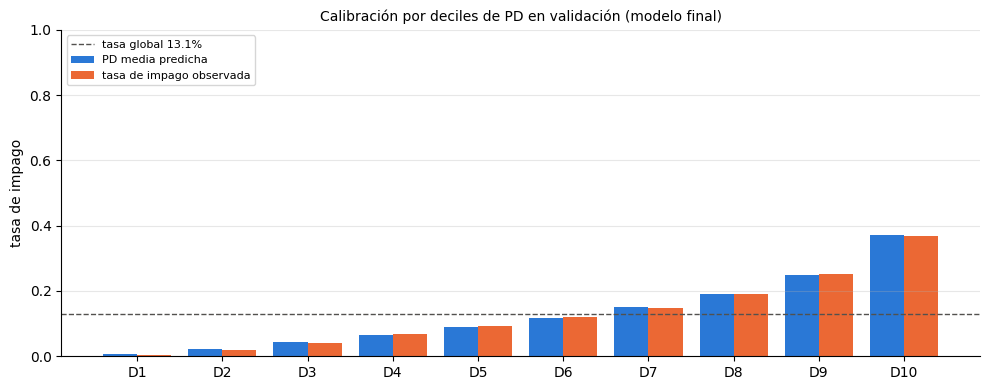

,n,PD media,tasa observada,PD / observada
decil de PD,,,,
D1,34235,0.006,0.005,1.187
D2,34234,0.023,0.021,1.100
D3,34234,0.044,0.040,1.092
D4,34234,0.067,0.068,0.981
D5,34235,0.091,0.093,0.978
D6,34234,0.117,0.120,0.978
D7,34234,0.150,0.149,1.003
D8,34234,0.190,0.190,1.001
D9,34234,0.249,0.253,0.984


,n,PD media,tasa observada,PD / observada
% plazo transcurrido,,,,
0-10%,28222,0.012,0.012,1.032
10-25%,39586,0.050,0.050,1.018
25-50%,55029,0.111,0.109,1.018
50-75%,61530,0.177,0.175,1.010
75-99%,50056,0.187,0.190,0.984
100%,107920,0.148,0.150,0.993


In [23]:
# 2) Calibración por deciles de PD
decil_pd = pd.qcut(pd_val, 10, labels=[f"D{i}" for i in range(1, 11)]).rename("decil de PD")
calib_deciles = pd.DataFrame({
    "n": pd_val.groupby(decil_pd, observed=True).size(),
    "PD media": pd_val.groupby(decil_pd, observed=True).mean(),
    "tasa observada": y_val.groupby(decil_pd, observed=True).mean(),
})
calib_deciles["PD / observada"] = calib_deciles["PD media"] / calib_deciles["tasa observada"]

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(calib_deciles))
ax.bar(x - 0.2, calib_deciles["PD media"], width=0.4, color=COLOR_NO_IMPAGO, label="PD media predicha")
ax.bar(x + 0.2, calib_deciles["tasa observada"], width=0.4, color=COLOR_IMPAGO, label="tasa de impago observada")
ax.axhline(y_val.mean(), color=COLOR_REF, ls="--", lw=1, label=f"tasa global {y_val.mean():.1%}")
ax.set_xticks(x, calib_deciles.index)
ax.set_ylim(0, 1)
ax.set_ylabel("tasa de impago")
ax.set_title("Calibración por deciles de PD en validación (modelo final)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
display(calib_deciles.round(3))

# 3) Calibración por tramo de madurez
tramo_val = pd.cut(val["pct_plazo_transcurrido"], CORTES_MADUREZ, labels=ETIQUETAS_MADUREZ).rename("% plazo transcurrido")
calib_madurez = pd.DataFrame({
    "n": pd_val.groupby(tramo_val, observed=True).size(),
    "PD media": pd_val.groupby(tramo_val, observed=True).mean(),
    "tasa observada": y_val.groupby(tramo_val, observed=True).mean(),
})
calib_madurez["PD / observada"] = calib_madurez["PD media"] / calib_madurez["tasa observada"]
calib_madurez.round(3)

## 8. Exportar la PD para el notebook de EAD, LGD y ECL

El modelo de PD está cerrado. Los modelos de EAD y LGD, el cálculo del ECL y el margen conservador se hacen en el tercer notebook, `03_ead_lgd_ecl.ipynb`, que necesita la **PD de cada préstamo de validación y de test**.

**Qué hace la celda**:
- Aplica `modelo_pd` (sección 7) a validación y a test.
- Guarda las dos series en `data/processed/pd_val_test.pkl`, con:
  - el **índice original** de cada préstamo;
  - la partición (`val` / `test`);
  - el `impago` observado, que el segundo notebook usa solo para comprobar que las filas casan.

**¿Predecir la PD de test es "mirar test"?** No. Solo se usan sus **variables de originación**, igual que se haría con un préstamo nuevo; su target no interviene en nada. Test se sigue sin usar para entrenar, elegir modelos ni ajustar el margen.

**Por qué guardar las predicciones y no el modelo**: `modelo_pd` incluye clases definidas en este notebook (`ImputadorConFlag`, `Winsorizer`...). Cargarlo con pickle en otro notebook obligaría a copiar esas clases. Las predicciones, en cambio, son solo números.

**Por qué `.pkl`**: es el formato nativo de pandas y conserva el índice y los tipos sin instalar nada (parquet necesitaría `pyarrow`).

**Cómo leer la salida**: número de préstamos y PD media de cada partición, que debe estar cerca de la tasa de impago (~13%). El assert comprueba que las PD de validación coinciden con las de la sección 7.

In [24]:
RUTA_PD = "data/processed/pd_val_test.pkl"

pd_test = pd.Series(modelo_pd.predict_proba(test[cols_pd])[:, 1], index=test.index, name="pd")
assert np.allclose(modelo_pd.predict_proba(val[cols_pd])[:, 1], pd_val), "La PD de validación no coincide con 7.1"

exportar = pd.concat([
    pd.DataFrame({"pd": pd_val, "particion": "val", "impago": val["impago"]}),
    pd.DataFrame({"pd": pd_test, "particion": "test", "impago": test["impago"]}),
])
exportar.to_pickle(RUTA_PD)
print(f"Guardado en {RUTA_PD}")
exportar.groupby("particion").agg(n=("pd", "size"), pd_media=("pd", "mean")).round(4)

Guardado en data/processed/pd_val_test.pkl


,n,pd_media
particion,,
test,427929,0.1306
val,342343,0.1307
